# Multiclass Skin Lesion Classification Using CNNs

## 1. Project Overview

This notebook develops and evaluates image-based deep learning
models for multiclass skin lesion classification using the
PAD-UFES-20 dataset.

The objective is to classify skin lesion
images into six diagnostic categories:

- ACK – Actinic Keratosis
- BCC – Basal Cell Carcinoma
- MEL – Melanoma
- NEV – Nevus
- SCC – Squamous Cell Carcinoma
- SEK – Seborrheic Keratosis

The experiments compare a custom CNN with pretrained CNN
architectures using transfer learning and fine-tuning.

Model selection is performed using validation performance and
patient-level cross-validation. A separate held-out test set is
reserved for final evaluation.





In [1]:
# ===== Google Colab setup (skipped automatically when run elsewhere) =====
import os

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DRIVE_DATASET = "/content/drive/MyDrive/Colab Notebooks/ML/PAD-UFES Dataset.zip"   # a .zip file OR a folder in your Drive
DRIVE_OUT     = "/content/drive/MyDrive/Colab Notebooks/ML/skin_lesion_artifacts"  # results are saved here

if IN_COLAB:
    drive.mount("/content/drive")
    if DRIVE_DATASET.lower().endswith(".zip"):
        import zipfile
        target = "/content/pad_ufes_data"
        if not os.path.isdir(target):
            print("Unzipping dataset (one-off, ~1-2 min)...")
            with zipfile.ZipFile(DRIVE_DATASET) as z:
                z.extractall(target)
        DRIVE_DATASET = target
    print("Colab ready. Dataset:", DRIVE_DATASET)
else:
    print("Not running on Colab: using local paths")

Not running on Colab: using local paths


**Step 1: Specifying the problem:**  
###### To develop a model that can classify skin lesions into the 6 different classes (includes both cancerous and non-cancerous lesions)

**Step 2: Get the dataset:**  
###### We used the PAD-UFES-20 Dataset. 
###### Dataset Source: (Kaggle link) -  https://www.kaggle.com/datasets/mahdavi1202/skin-cancer/data 
###### The paper publication/Original dataset paper - https://www.sciencedirect.com/science/article/pii/S235234092031115X?via%3Dihub

In [2]:
# Import libaries
import os, random, hashlib, json
from types import SimpleNamespace
from pathlib import Path
from collections import Counter
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess_input
from tensorflow.keras.applications import EfficientNetB0

# Sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, classification_report,
                             matthews_corrcoef, roc_curve, auc)


In [3]:
# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Improve reproducibility where supported.
# This can reduce performance slightly.
tf.keras.utils.set_random_seed(SEED)


#Visualisation settings
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

%matplotlib inline

## 2. Dataset Description

The PAD-UFES-20 dataset is used for image-based classification.

The original dataset contains 2,298 images across six diagnostic
classes. Before model training, identical images are identified
using SHA-256 hashing and duplicate records are handled.



In [4]:
# Dataset path
# ---------------- configuration ----------------
CLASSES     = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]   # fixed label order
NUM_CLASSES = len(CLASSES)
IMG_SIZE    = 224
BATCH_SIZE  = 32

# Patient-level data splitting
N_FOLDS     = 5
TEST_FOLD   = 0           # held-out test set (~20%)
VAL_FOLD    = 1           # validation set (~20%); remaining 3 folds (~60%) = train

QUICK_TEST  = False       # True = tiny 1-epoch run to check the code works
RETRAIN     = True
EPOCHS      = 1 if QUICK_TEST else 50

# ImageNet pretrained weights for transfer learning
PRETRAINED  = "imagenet"  # None = do not download pretrained weights

# Dataset location. On Colab it comes from the setup cell above.
# Elsewhere: set the PAD_UFES_DIR environment variable, or type a path here.
MANUAL_DATASET_DIR = DRIVE_DATASET if IN_COLAB else None   # e.g. "D:/data/PAD-UFES Dataset"

# Use the existing Colab output directory if available.
# Otherwise, save results locally.

if IN_COLAB:
    OUT_DIR = Path(DRIVE_OUT)
else:
    OUT_DIR = Path("skin_lesion_artifacts")

OUT_DIR.mkdir(parents=True, exist_ok=True)


#Environment checks

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs:", gpus)

if not gpus:
    print("WARNING: No GPU detected.")
    print("For Colab, select Runtime > Change runtime type > GPU.")

print("\nConfiguration:")
print("Classes:", CLASSES)
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Output directory:", OUT_DIR.resolve())


TensorFlow version: 2.21.0
Available GPUs: []
For Colab, select Runtime > Change runtime type > GPU.

Configuration:
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Number of classes: 6
Image size: 224
Batch size: 32
Epochs: 50
Output directory: C:\Users\Kanakan\Skin Lesion Classification\PG-Group-3---Multimodal-Skin-Lesion-Classification-Skin-Cancer-Detection-\Image_EDA_and_Training\skin_lesion_artifacts


In [5]:

# 1. Find the dataset directory


def find_dataset_dir():
    """Find the directory containing metadata.csv."""

    candidates = []

    if MANUAL_DATASET_DIR:
        manual = Path(MANUAL_DATASET_DIR).expanduser()
        candidates.append(manual)

        if manual.is_dir():
            candidates.extend(
                p.parent for p in manual.rglob("metadata.csv")
            )

    if os.environ.get("PAD_UFES_DIR"):
        candidates.append(Path(os.environ["PAD_UFES_DIR"]))

    here = Path.cwd().resolve()

    for base in [here, *list(here.parents)[:3]]:
        candidates.append(base)

        for folder_name in [
            "PAD-UFES Dataset",
            "PAD-UFES-20",
            "PAD-UFES",
            "pad-ufes-20"
        ]:
            candidates.append(base / folder_name)
            candidates.append(base / "data" / folder_name)

    # Remove duplicate candidate paths
    checked = set()

    for candidate in candidates:
        candidate = candidate.expanduser()

        if candidate in checked:
            continue

        checked.add(candidate)

        if (candidate / "metadata.csv").is_file():
            return candidate.resolve()

    raise FileNotFoundError(
        "Dataset not found. Check MANUAL_DATASET_DIR "
        "or the PAD_UFES_DIR environment variable."
    )


# ============================================================
# 2. IMAGE READING FUNCTION
# ============================================================

def read_image(path):
    """
    Read an image using OpenCV and convert BGR to RGB.
    np.fromfile + imdecode also supports non-English Windows paths.
    """

    img = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    if img is None:
        raise IOError(f"Could not read image: {path}")

    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# ============================================================
# 3. LOCATE IMAGE FOLDERS AND FILES
# ============================================================

DATASET_DIR = find_dataset_dir()

print("Dataset directory:", DATASET_DIR)

# Find all imgs_part_* directories
IMAGE_DIRS = sorted(
    p for p in DATASET_DIR.glob("imgs_part_*")
    if p.is_dir()
)

if not IMAGE_DIRS:
    raise FileNotFoundError(
        "No imgs_part_* directories found inside the dataset folder."
    )

# Search recursively for PNG images
files = [
    p
    for folder in IMAGE_DIRS
    for p in folder.rglob("*")
    if p.is_file() and p.suffix.lower() == ".png"
]

if not files:
    raise FileNotFoundError("No PNG images found.")

# Create filename-to-path lookup
paths = {}

for p in files:
    if p.name in paths:
        raise ValueError(
            f"Duplicate filename found in image folders: {p.name}\n"
            f"First location: {paths[p.name]}\n"
            f"Second location: {p}"
        )

    paths[p.name] = p

print("Image folders found:", len(IMAGE_DIRS))
print("Image files found:", len(files))


# ============================================================
# 4. LOAD AND VALIDATE METADATA
# ============================================================

meta = pd.read_csv(DATASET_DIR / "metadata.csv")

# Check required columns
required_columns = [
    "img_id",
    "patient_id",
    "lesion_id",
    "diagnostic"
]

missing_columns = [
    col for col in required_columns
    if col not in meta.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required metadata columns: {missing_columns}"
    )

# Check image IDs
if meta["img_id"].isna().any():
    raise ValueError("Missing image IDs found in metadata.")

meta["img_id"] = meta["img_id"].astype(str).str.strip()

if meta["img_id"].duplicated().any():
    raise ValueError("Repeated img_id values found in metadata.csv.")

# Check diagnosis labels
if not meta["diagnostic"].isin(CLASSES).all():
    unexpected = meta.loc[
        ~meta["diagnostic"].isin(CLASSES),
        "diagnostic"
    ].unique()

    raise ValueError(
        f"Unexpected or missing diagnosis labels: {unexpected}"
    )

# Match metadata image IDs to actual image paths
meta["path"] = meta["img_id"].map(paths)

if meta["path"].isna().any():
    missing_images = meta.loc[
        meta["path"].isna(), "img_id"
    ].tolist()

    raise FileNotFoundError(
        f"{len(missing_images)} metadata images were not found. "
        f"Examples: {missing_images[:10]}"
    )

meta["path"] = meta["path"].astype(str)

# Display loading summary
print("\nDataset loaded successfully")
print("Metadata rows:", len(meta))
print("Image folders:", len(IMAGE_DIRS))
print("Image files:", len(files))
print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASSES)

print("\nOriginal class distribution:")
print(meta["diagnostic"].value_counts().reindex(CLASSES))

Dataset directory: C:\Users\Kanakan\Skin Lesion Classification\PG-Group-3---Multimodal-Skin-Lesion-Classification-Skin-Cancer-Detection-\Image_EDA_and_Training\PAD-UFES Dataset
Image folders found: 3
Image files found: 2298

Dataset loaded successfully
Metadata rows: 2298
Image folders: 3
Image files: 2298
Number of classes: 6
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']

Original class distribution:
diagnostic
ACK    730
BCC    845
MEL     52
NEV    244
SCC    192
SEK    235
Name: count, dtype: int64


In [6]:
# ============================================================
# 5. IDENTIFY BYTE-IDENTICAL DUPLICATE IMAGES
# ============================================================

def image_hash(path):
    """Calculate SHA-256 hash of an image file."""

    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()


meta["image_hash"] = meta["path"].map(image_hash)

# Find groups of identical images
duplicate_groups = meta.groupby("image_hash")

drop_reasons = {}
duplicate_summary = []

for image_hash_value, group in duplicate_groups:

    if len(group) <= 1:
        continue

    labels = group["diagnostic"].unique()

    # Case 1: All identical images have the same diagnosis
    if len(labels) == 1:

        # Keep the first copy and remove the remaining copies
        indices_to_drop = group.index.tolist()[1:]

        for idx in indices_to_drop:
            drop_reasons[idx] = "Identical image - same diagnosis"

        reason = "Same diagnosis - kept one copy"

    # Case 2: Identical images have conflicting diagnoses
    else:

        # Exclude every copy from the modelling dataset
        indices_to_drop = group.index.tolist()

        for idx in indices_to_drop:
            drop_reasons[idx] = "Identical image - conflicting diagnoses"

        reason = "Conflicting diagnoses - excluded all copies"

    duplicate_summary.append({
        "image_hash": image_hash_value,
        "number_of_copies": len(group),
        "diagnoses": ", ".join(sorted(labels)),
        "patient_ids": ", ".join(
            group["patient_id"].astype(str).unique()
        ),
        "lesion_ids": ", ".join(
            group["lesion_id"].astype(str).unique()
        ),
        "img_ids": ", ".join(group["img_id"].astype(str)),
        "action": reason
    })


# ============================================================
# 6. SAVE DUPLICATE AUDIT
# ============================================================

# Detailed information about duplicate groups
duplicate_summary_df = pd.DataFrame(duplicate_summary)

duplicate_summary_df.to_csv(
    OUT_DIR / "duplicate_group_audit.csv",
    index=False
)

# Details of individual rows excluded
dropped_indices = sorted(drop_reasons.keys())

dropped = meta.loc[dropped_indices].copy()

if len(dropped) > 0:
    dropped["removal_reason"] = [
        drop_reasons[idx] for idx in dropped.index
    ]

dropped.to_csv(
    OUT_DIR / "dropped_duplicates.csv",
    index=False
)


# ============================================================
# 7. CREATE CLEANED IMAGE DATAFRAME
# ============================================================

df = meta.drop(index=dropped_indices).reset_index(drop=True)

print("\nDuplicate removal summary")
print("-" * 45)

print("Original images:", len(meta))
print("Removed images:", len(dropped))
print("Remaining images:", len(df))
print("Duplicate groups:", len(duplicate_summary_df))

if len(dropped) > 0:
    print("\nRemoval reasons:")
    print(dropped["removal_reason"].value_counts())




Duplicate removal summary
---------------------------------------------
Original images: 2298
Removed images: 27
Remaining images: 2271
Duplicate groups: 15

Removal reasons:
removal_reason
Identical image - conflicting diagnoses    24
Identical image - same diagnosis            3
Name: count, dtype: int64


Class Distribution
----------------------------------------
Class  Count  Percentage
  ACK    723   31.836196
  BCC    834   36.723910
  MEL     52    2.289740
  NEV    243   10.700132
  SCC    185    8.146191
  SEK    234   10.303831


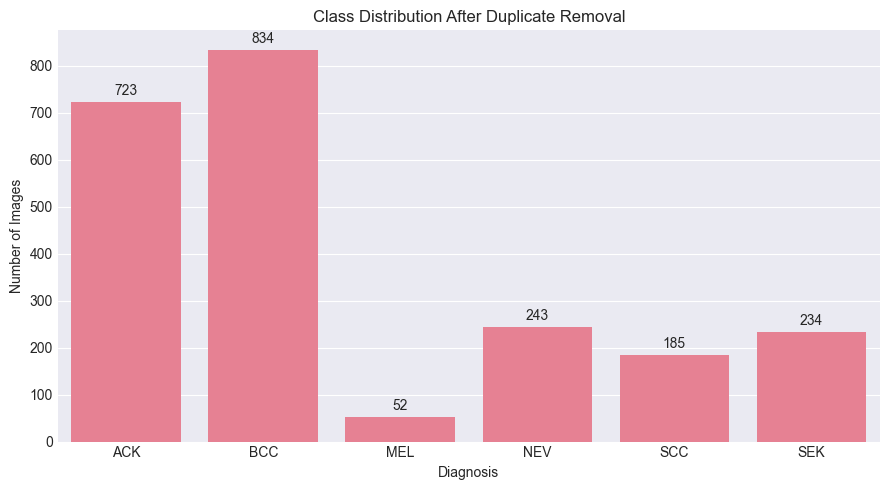


Total images: 2271
Number of classes: 6
Imbalance ratio: 16.04:1


In [7]:
# Analyse class distribution
class_order = CLASSES

counts = df["diagnostic"].value_counts().reindex(class_order, fill_value=0)

df_dist = pd.DataFrame({
    "Class": class_order,
    "Count": counts.values,
    "Percentage": (counts.values / len(df)) * 100
})

print("Class Distribution")
print("-" * 40)
print(df_dist.to_string(index=False))

# Visualise class distribution
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df_dist,
    x="Class",
    y="Count",
    order=class_order
)

ax.set_title("Class Distribution After Duplicate Removal")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of Images")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

# Calculate imbalance ratio
nonzero_counts = counts[counts > 0]
imbalance_ratio = nonzero_counts.max() / nonzero_counts.min()

print(f"\nTotal images: {len(df)}")
print(f"Number of classes: {len(class_order)}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

### Dataset Distribution Observations

After duplicate removal, 2,271 images remain.

The largest class is BCC, while MEL is the smallest class.
The majority-to-minority class imbalance ratio is approximately
16.04:1.

This imbalance motivates the investigation of class weighting,
focal loss and oversampling during model training.

## 3. Patient-Level Data Splitting

The dataset is divided into five stratified folds using
StratifiedGroupKFold, with patient_id used as the grouping variable.

This ensures that images belonging to the same patient are not
distributed across different folds.

The initial development arrangement is:

- Training: folds 2, 3 and 4
- Validation: fold 1
- Held-out test: fold 0

The test fold is reserved for final evaluation.

In [8]:

# ==========================================
# PATIENT-LEVEL STRATIFIED DATA SPLITTING
# ==========================================

# Encode diagnostic labels
label_mapping = {c: i for i, c in enumerate(CLASSES)}

df["label"] = df["diagnostic"].map(label_mapping).astype(int)

# Assign each patient to exactly one fold
df["fold"] = -1

sgkf = StratifiedGroupKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

for fold, (_, val_fold_idx) in enumerate(
    sgkf.split(
        X=df,
        y=df["label"],
        groups=df["patient_id"]
    )
):
    df.loc[val_fold_idx, "fold"] = fold

# Verify every image has a fold
assert (df["fold"] >= 0).all(), "Some images were not assigned to a fold!"

# Verify no patient appears in multiple folds
assert df.groupby("patient_id")["fold"].nunique().max() == 1

# Define training, validation and test indices
train_idx = np.where(
    ~df["fold"].isin([TEST_FOLD, VAL_FOLD])
)[0]

val_idx = np.where(df["fold"] == VAL_FOLD)[0]
test_idx = np.where(df["fold"] == TEST_FOLD)[0]

# Verify splits do not overlap
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

# Verify patient-level separation
train_patients = set(df.iloc[train_idx]["patient_id"])
val_patients = set(df.iloc[val_idx]["patient_id"])
test_patients = set(df.iloc[test_idx]["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

# Save the complete split assignment
df[
    ["img_id", "patient_id", "lesion_id",
     "diagnostic", "label", "fold"]
].to_csv(OUT_DIR / "splits.csv", index=False)

print("Split summary")
print("-" * 45)
print(f"Training:   {len(train_idx)} images | {len(train_patients)} patients")
print(f"Validation: {len(val_idx)} images | {len(val_patients)} patients")
print(f"Testing:    {len(test_idx)} images | {len(test_patients)} patients")

# ==========================================
# CHECK CLASS DISTRIBUTION
# ==========================================

split_counts = pd.DataFrame({
    "Full": df["diagnostic"].value_counts(),
    "Train": df.iloc[train_idx]["diagnostic"].value_counts(),
    "Validation": df.iloc[val_idx]["diagnostic"].value_counts(),
    "Test": df.iloc[test_idx]["diagnostic"].value_counts()
}).reindex(CLASSES, fill_value=0)

split_percentages = (
    split_counts.div(split_counts.sum(axis=0), axis=1) * 100
).round(2)

print("\nClass counts:")
display(split_counts)

print("\nClass percentages (%):")
display(split_percentages)

# Warn if any class is missing from a split
for split_name in ["Train", "Validation", "Test"]:
    missing = split_counts.index[split_counts[split_name] == 0].tolist()

    if missing:
        print(f"WARNING: {missing} missing from {split_name}")
    else:
        print(f"All classes represented in {split_name}.")

# ==========================================
# QUICK TEST SUBSET (OPTIONAL)
# ==========================================

if QUICK_TEST:
    rng = np.random.default_rng(SEED)

    # Randomly select training images for pipeline debugging only
    train_idx = rng.choice(
        train_idx,
        size=min(128, len(train_idx)),
        replace=False
    )

    print(f"\nQUICK TEST MODE: Using {len(train_idx)} training images.")


Split summary
---------------------------------------------
Training:   1373 images | 823 patients
Validation: 430 images | 273 patients
Testing:    468 images | 275 patients

Class counts:


,Full,Train,Validation,Test
diagnostic,,,,
ACK,723,434,130,159
BCC,834,510,164,160
MEL,52,35,8,9
NEV,243,150,41,52
SCC,185,106,33,46
SEK,234,138,54,42



Class percentages (%):


,Full,Train,Validation,Test
diagnostic,,,,
ACK,31.84,31.61,30.23,33.97
BCC,36.72,37.14,38.14,34.19
MEL,2.29,2.55,1.86,1.92
NEV,10.70,10.92,9.53,11.11
SCC,8.15,7.72,7.67,9.83
SEK,10.30,10.05,12.56,8.97


All classes represented in Train.
All classes represented in Validation.
All classes represented in Test.


## 4. Image Preprocessing

All images are converted to RGB and resized  to 224 × 224 pixels.

The resized images are stored in a cache to avoid repeatedly
processing the original image files.

Labels are integer-encoded according to the predefined class order.

In [9]:

# ==========================================
# IMAGE RESIZING AND CACHING
# ==========================================

cache_version = "v2_rgb_resize_area"
cache_file = OUT_DIR / f"images_{IMG_SIZE}_{cache_version}.npz"

# Image IDs in the exact order of df
ids = np.array(df["img_id"].tolist(), dtype="U")

X = None

# Try loading an existing cache
if cache_file.exists():

    with np.load(cache_file, allow_pickle=False) as cache:

        cached_ids = cache["ids"]
        cached_version = str(cache["version"].item())

        if (
            np.array_equal(cached_ids, ids)
            and cached_version == cache_version
            and cache["images"].shape == (
                len(df), IMG_SIZE, IMG_SIZE, 3
            )
        ):
            X = cache["images"]
            print("Loaded valid image cache.")

        else:
            print("Cache does not match current dataset/settings.")
            print("Rebuilding image cache.")

# Build cache if necessary
if X is None:

    X = np.zeros(
        (len(df), IMG_SIZE, IMG_SIZE, 3),
        dtype=np.uint8
    )

    for i, path in enumerate(df["path"]):

        img = read_image(path)

        resized = cv2.resize(
            img,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )

        X[i] = resized

        if (i + 1) % 500 == 0 or (i + 1) == len(df):
            print(f"Resized {i + 1}/{len(df)} images")

    # Save images and cache information
    np.savez(
        cache_file,
        images=X,
        ids=ids,
        version=np.array(cache_version)
    )

    print(f"Saved image cache: {cache_file}")

# ==========================================
# LABELS
# ==========================================

# Integer-encoded labels
y = df["label"].to_numpy(dtype=np.int32)

NUM_CLASSES = len(CLASSES)

print("\nDataset arrays:")
print("Images:", X.shape, X.dtype)
print("Labels:", y.shape, y.dtype)
print("Number of classes:", NUM_CLASSES)

# Check image and label consistency
assert len(X) == len(y)
assert X.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert y.min() >= 0 and y.max() < NUM_CLASSES


Loaded valid image cache.

Dataset arrays:
Images: (2271, 224, 224, 3) uint8
Labels: (2271,) int32
Number of classes: 6


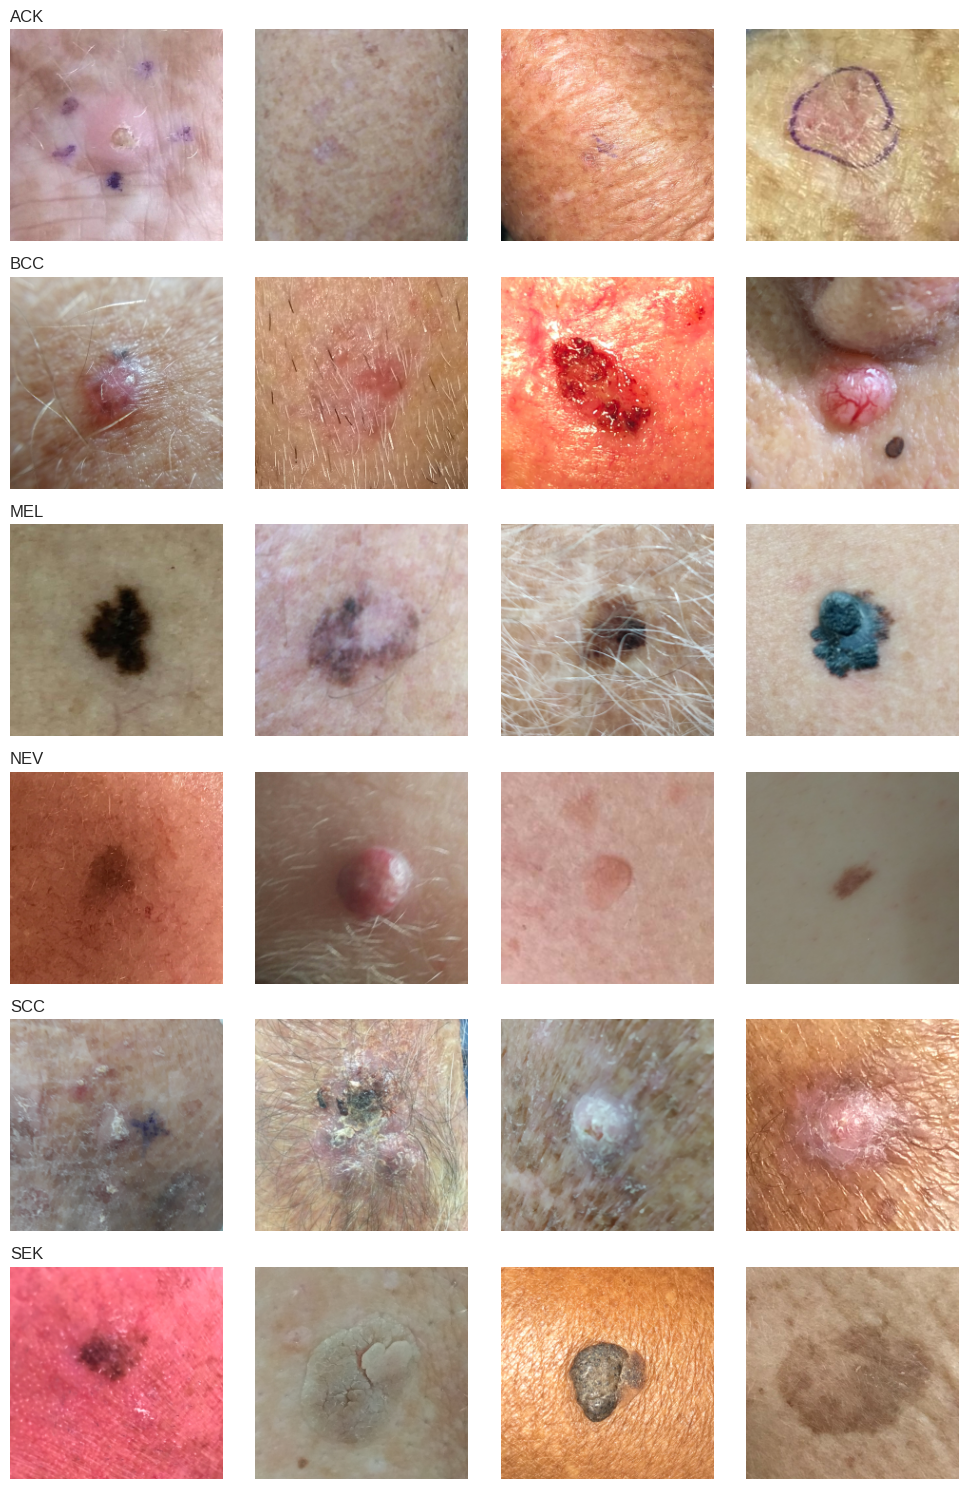

In [ ]:
# sample images
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(10, 15))
rng = np.random.default_rng(SEED)
for r, c in enumerate(CLASSES):
    chosen = rng.choice(np.where(y == CLASSES.index(c))[0], 4, replace=False)
    for col, i in enumerate(chosen):
        axes[r, col].imshow(X[i]); axes[r, col].axis("off")
        if col == 0:
            axes[r, col].set_title(c, loc="left")
plt.tight_layout(); plt.show()

In [10]:

# ==========================================
# CREATE TENSORFLOW DATASETS
# ==========================================

def make_ds(idx, training=False):

    # Use cached images and integer labels
    ds = tf.data.Dataset.from_tensor_slices((X[idx], y[idx]))

    # Shuffle training data only
    if training:
        ds = ds.shuffle(
            buffer_size=len(idx),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Batch and prefetch
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Create datasets
train_ds = make_ds(train_idx, training=True)
val_ds = make_ds(val_idx, training=False)
test_ds = make_ds(test_idx, training=False)

print("Dataset summary")
print("-" * 40)
print(f"Training batches:   {len(train_ds)}")
print(f"Validation batches: {len(val_ds)}")
print(f"Testing batches:    {len(test_ds)}")


Dataset summary
----------------------------------------
Training batches:   43
Validation batches: 14
Testing batches:    15


## 5. Data Augmentation and Class Imbalance Handling

Data augmentation is applied to training images to introduce
controlled variations and reduce overfitting.

Three imbalance-handling approaches are investigated:

1. Class weighting.
2. Focal loss.
3. Random oversampling of minority classes.

Validation and test datasets are not augmented or oversampled.

In [11]:

# ==========================================
# DATA AUGMENTATION
# ==========================================

augment = keras.Sequential([

    # Random horizontal and vertical flips
    layers.RandomFlip("horizontal_and_vertical"),

    # Small rotations
    layers.RandomRotation(0.10,fill_mode="reflect" ),

    # Moderate zoom
    layers.RandomZoom(0.10,fill_mode="reflect" ),

    # Small contrast variation
    layers.RandomContrast(0.10),

], name="augmentation")


print("Augmentation pipeline created.")


Augmentation pipeline created.


In [12]:
# Handle Imbalanced data

# Compute class weights using training data only
present = np.unique(y[train_idx])

weights_array = compute_class_weight(
    class_weight="balanced",
    classes=present,
    y=y[train_idx]
)

class_weights = {
    int(c): float(w)
    for c, w in zip(present, weights_array)
}

print("Class Weights:")
for i, class_name in enumerate(CLASSES):
    print(f"  {class_name}: {class_weights[i]:.3f}")

Class Weights:
  ACK: 0.527
  BCC: 0.449
  MEL: 6.538
  NEV: 1.526
  SCC: 2.159
  SEK: 1.658


In [13]:
# Focal Loss for integer-encoded labels
class SparseFocalLoss(keras.losses.Loss):

    def __init__(self, gamma=2.0, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma

    def call(self, y_true, y_pred):

        # Convert labels to integer format
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)

        # Avoid numerical instability
        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1.0 - 1e-7
        )

        # Select probability of the correct class
        indices = tf.stack(
            [tf.range(tf.shape(y_true)[0]), y_true],
            axis=1
        )

        pt = tf.gather_nd(y_pred, indices)

        # Calculate focal loss
        focal_loss = -tf.pow(1.0 - pt, self.gamma) * tf.math.log(pt)

        return focal_loss

    def get_config(self):
        config = super().get_config()
        config.update({"gamma": self.gamma})
        return config

In [14]:
# Oversampling pipeline
# Calculate the number of training samples in each class
train_counts = np.bincount(
    y[train_idx],
    minlength=NUM_CLASSES
)

# Use the median class count as the target
target_count = int(np.ceil(np.median(train_counts)))

print("Original training distribution:")

for i, class_name in enumerate(CLASSES):
    print(f"{class_name}: {train_counts[i]}")

print(f"\nOversampling target: {target_count}")


Original training distribution:
ACK: 434
BCC: 510
MEL: 35
NEV: 150
SCC: 106
SEK: 138

Oversampling target: 144


In [15]:
# Generate oversampled training indices
# Oversample minority classes while retaining all original samples
rng = np.random.default_rng(SEED)

oversampled_indices = []

for class_id in range(NUM_CLASSES):

    # Get original training indices for this class
    class_indices = train_idx[y[train_idx] == class_id]

    # Keep all original samples
    oversampled_class = list(class_indices)

    # Add samples with replacement if below the target
    if len(class_indices) < target_count:

        additional_samples = rng.choice(
            class_indices,
            size=target_count - len(class_indices),
            replace=True
        )

        oversampled_class.extend(additional_samples)

    oversampled_indices.extend(oversampled_class)

# Shuffle the combined indices
oversampled_indices = np.array(
    oversampled_indices,
    dtype=np.int32
)

rng.shuffle(oversampled_indices)

# Check the resulting distribution
oversampled_counts = np.bincount(
    y[oversampled_indices],
    minlength=NUM_CLASSES
)

print("\nOversampled training distribution:")

for i, class_name in enumerate(CLASSES):
    print(f"{class_name}: {oversampled_counts[i]}")

print(f"\nOriginal training size: {len(train_idx)}")
print(f"Oversampled training size: {len(oversampled_indices)}")


Oversampled training distribution:
ACK: 434
BCC: 510
MEL: 144
NEV: 150
SCC: 144
SEK: 144

Original training size: 1373
Oversampled training size: 1526


In [16]:
# Create oversampled training pipeline
train_ds_oversampled = make_ds(
    oversampled_indices,
    training=True
)

**Step 3: Design the Models**

## 6. Custom CNN Architecture

A custom CNN is implemented as the baseline model.

The architecture consists of three convolutional blocks with
32, 64 and 128 filters, followed by global average pooling,
dropout and a six-class softmax output layer.

Batch Normalisation and ReLU activation are used within the
convolutional blocks.

Four experiments investigate different training strategies:
baseline, class weighting, focal loss and oversampling.

#### Simple CNN implementations

| **Exp #** | **Architecture** | **Strategy** | **Loss Function** |
| --------- | ---------------- | ------------ | ----------------- |
| 1 | Simple CNN | Baseline | Cross-Entropy |
| 2 | Simple CNN | Class Weighting | Cross-Entropy |
| 3 | Simple CNN | Focal Loss | Focal Loss |
| 4 | Simple CNN | Oversampling | Cross-Entropy |

In [17]:
def create_simple_cnn(lr=0.001, dropout=0.4, use_focal=False, use_augmentation=True, use_bn=True, bn_momentum=0.9):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp) if use_augmentation else inp
    x = layers.Rescaling(1./255)(x)

    x = layers.Conv2D(32,3,padding="same",use_bias=False)(x)
    if use_bn: x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(64,3,padding="same",use_bias=False)(x)
    if use_bn: x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128,3,padding="same",use_bias=False)(x)
    if use_bn: x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES,activation="softmax")(x)

    model = keras.Model(inp,out,name="Simple_CNN")
    loss = SparseFocalLoss(gamma=2.0) if use_focal else keras.losses.SparseCategoricalCrossentropy()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),loss=loss,metrics=["accuracy"])
    return model

In [18]:
model = create_simple_cnn()
model.summary()

Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ augmentation (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 224, 224, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 94,694 (369.90 KB)

 Trainable params: 94,246 (368.15 KB)

 Non-trainable params: 448 (1.75 KB)

In [19]:
# Create output folders
MODEL_DIR = OUT_DIR / "models"
RESULT_DIR = OUT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Storage for results
results = {}
histories = {}

In [20]:
class ValidationMacroF1(keras.callbacks.Callback):
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):
        y_true, y_pred = [], []
        for images, labels in self.val_ds:
            probs = self.model(images, training=False).numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(np.argmax(probs, axis=1))

        score = f1_score(y_true, y_pred, average="macro", zero_division=0)
        logs["val_macro_f1"] = score
        print(f" - val_macro_f1: {score:.4f}")

In [21]:
# Training callbacks
def get_callbacks(name, val_data=None):
    vd = val_ds if val_data is None else val_data
    return [
        ValidationMacroF1(vd),
        keras.callbacks.ModelCheckpoint(str(MODEL_DIR / f"{name}_best.weights.h5"),
                                        monitor="val_macro_f1", mode="max",
                                        save_best_only=True, save_weights_only=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5,
                                          patience=5, min_lr=1e-6, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=10,
                                      min_delta=0.0, restore_best_weights=True, verbose=1)
    ]

In [22]:
def run_cnn_experiment(name, train_data, use_focal=False, class_weight=None):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = create_simple_cnn(use_focal=use_focal)
    checkpoint = MODEL_DIR / f"{name}_best.weights.h5"

    history = model.fit(train_data, validation_data=val_ds, epochs=EPOCHS,
                        class_weight=class_weight, callbacks=get_callbacks(name), verbose=1)

    # Reload the best macro-F1 checkpoint
    model.load_weights(checkpoint)

    # Store and save training history
    histories[name] = history.history
    pd.DataFrame(history.history).to_csv(RESULT_DIR / f"{name}_history.csv", index_label="epoch")

    with open(RESULT_DIR / "cnn_histories.pkl", "wb") as f:
        pickle.dump(histories, f)

    # Record best validation results
    best_idx = int(np.argmax(history.history["val_macro_f1"]))
    results[name] = {
        "best_epoch": best_idx + 1,
        "best_val_macro_f1": history.history["val_macro_f1"][best_idx],
        "val_loss_at_best_f1": history.history["val_loss"][best_idx],
        "val_accuracy_at_best_f1": history.history["val_accuracy"][best_idx],
        "epochs_trained": len(history.history["loss"])
    }

    pd.DataFrame(results).T.to_csv(RESULT_DIR / "cnn_results.csv", index=True)

    print(f"\n{name} completed")
    print(f"Best epoch: {best_idx + 1}")
    print(f"Best validation macro-F1: {history.history['val_macro_f1'][best_idx]:.4f}")
    print(f"Saved weights: {checkpoint}")

    return model, history

### CNN Sanity Check: Ability to Overfit a Small Training Sample

Purpose

Verify that the custom CNN can learn and memorise a small, balanced sample when augmentation and dropout are disabled. This is a debugging check of the model implementation, not a measure of generalisation.


In [ ]:
# CNN sanity check - overfitting a small sample

# Select 8 images per class for overfitting test
rng = np.random.default_rng(SEED)
small_idx = np.concatenate([rng.choice(train_idx[y[train_idx]==c],8,replace=False) for c in range(NUM_CLASSES)])

print("Selected images:",len(small_idx))
print("Class distribution:",np.bincount(y[small_idx],minlength=NUM_CLASSES))

Selected images: 48
Class distribution: [8 8 8 8 8 8]


In [ ]:
# Create a single-batch dataset for overfitting test
small_train_ds = tf.data.Dataset.from_tensor_slices((X[small_idx],y[small_idx])).shuffle(len(small_idx),seed=SEED).batch(16).prefetch(tf.data.AUTOTUNE)
small_eval_ds = tf.data.Dataset.from_tensor_slices((X[small_idx],y[small_idx])).batch(16).prefetch(tf.data.AUTOTUNE)

print("Training batches:",len(small_train_ds))
print("Evaluation batches:",len(small_eval_ds))

Training batches: 3
Evaluation batches: 3


In [ ]:
class SaveBestWeights(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.best_acc = -1
        self.best_epoch = 0
        self.best_loss = None
        self.best_weights = None

    def on_epoch_end(self,epoch,logs=None):
        acc = logs["accuracy"]
        if acc > self.best_acc:
            self.best_acc = acc
            self.best_epoch = epoch + 1
            self.best_loss = logs["loss"]
            self.best_weights = self.model.get_weights()

best_callback = SaveBestWeights()

overfit_model = create_simple_cnn(dropout=0.0,use_augmentation=False,use_bn=True)
overfit_history = overfit_model.fit(small_train_ds,epochs=200,callbacks=[best_callback],verbose=1)

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.2083 - loss: 2.1788
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2917 - loss: 1.6949
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3333 - loss: 1.4997
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4583 - loss: 1.4361
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5208 - loss: 1.2936
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5625 - loss: 1.2520
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5625 - loss: 1.2215
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5000 - loss: 1.1829
Epoch 9/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5208 - loss: 1.2801
Epoch 10/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5833 - loss: 1.0836
Epoch 11/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6667 - loss: 1.0515
Epoch 12/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6875 - lo

In [ ]:
overfit_model.set_weights(best_callback.best_weights)

eval_loss,eval_acc = overfit_model.evaluate(small_eval_ds,verbose=0)

print(f"Best epoch: {best_callback.best_epoch}")
print(f"Best training accuracy: {best_callback.best_acc:.4f}")
print(f"Training loss at best epoch: {best_callback.best_loss:.4f}")
print(f"Inference-mode accuracy: {eval_acc:.4f}")
print(f"Inference-mode loss: {eval_loss:.4f}")

Best epoch: 88
Best training accuracy: 1.0000
Training loss at best epoch: 0.1985
Inference-mode accuracy: 0.9167
Inference-mode loss: 0.3273


In [ ]:
train_mode_preds = np.argmax(overfit_model(X[small_idx],training=True).numpy(),axis=1)
infer_mode_preds = np.argmax(overfit_model(X[small_idx],training=False).numpy(),axis=1)

print("Training-mode accuracy:",np.mean(train_mode_preds==y[small_idx]))
print("Inference-mode accuracy:",np.mean(infer_mode_preds==y[small_idx]))

Training-mode accuracy: 1.0
Inference-mode accuracy: 0.9375


In [ ]:
test_model = create_simple_cnn(lr=0.0003,dropout=0.0,use_augmentation=False,use_bn=False)
test_callback = SaveBestWeights()
test_history = test_model.fit(small_train_ds,epochs=300,callbacks=[test_callback],verbose=1)

test_model.set_weights(test_callback.best_weights)

train_preds = np.argmax(test_model(X[small_idx],training=True).numpy(),axis=1)
infer_preds = np.argmax(test_model(X[small_idx],training=False).numpy(),axis=1)

print("Best epoch:",test_callback.best_epoch)
print("Best training accuracy:",test_callback.best_acc)
print("Training-mode accuracy:",np.mean(train_preds==y[small_idx]))
print("Inference-mode accuracy:",np.mean(infer_preds==y[small_idx]))

Epoch 1/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.0833 - loss: 1.8021
Epoch 2/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1250 - loss: 1.7950
Epoch 3/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1667 - loss: 1.7908
Epoch 4/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1667 - loss: 1.7891
Epoch 5/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1667 - loss: 1.7878
Epoch 6/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1667 - loss: 1.7899
Epoch 7/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1875 - loss: 1.7867
Epoch 8/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1875 - loss: 1.7863
Epoch 9/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1875 - loss: 1.7852
Epoch 10/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1875 - loss: 1.7840
Epoch 11/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1875 - loss: 1.7840
Epoch 12/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1667 - lo

In [ ]:
small_train_ds = (tf.data.Dataset.from_tensor_slices((X[small_idx],y[small_idx]))
                  .shuffle(len(small_idx),seed=SEED).batch(16))

keras.backend.clear_session()
m = create_simple_cnn(lr=0.001,dropout=0.0,use_augmentation=False,use_bn=True,bn_momentum=0.9)
h = m.fit(small_train_ds,epochs=300,verbose=0)

xs,ys = X[small_idx],y[small_idx]

# Inference before refreshing BatchNorm statistics
acc_infer = (m(xs,training=False).numpy().argmax(1)==ys).mean()

# Training-mode accuracy
acc_train = (m(xs,training=True).numpy().argmax(1)==ys).mean()

# Refresh BatchNorm statistics using the complete sample
for _ in range(20):
    m(xs,training=True)

# Inference after refreshing BatchNorm statistics
acc_infer_refreshed = (m(xs,training=False).numpy().argmax(1)==ys).mean()

print("Epochs:",len(h.history["loss"]),"| Final loss:",round(h.history["loss"][-1],4))
print(f"Inference before refresh: {acc_infer:.3f}")
print(f"Training mode: {acc_train:.3f}")
print(f"Inference after refresh: {acc_infer_refreshed:.3f}")

Epochs: 300 | Final loss: 0.1439
Inference before refresh: 0.396
Training mode: 0.979
Inference after refresh: 0.938


In [ ]:
# Predict all 48 training images in inference mode
small_images = X[small_idx]
small_labels = y[small_idx]

pred_probs = m(small_images, training=False).numpy()
pred_labels = np.argmax(pred_probs, axis=1)

class_names = ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
# Compare actual and predicted labels
for i in range(len(small_labels)):
    actual = class_names[small_labels[i]]
    predicted = class_names[pred_labels[i]]
    confidence = pred_probs[i].max()
    print(f"{i+1:02d} | Actual: {actual:3s} | Predicted: {predicted:3s} | Confidence: {confidence:.3f}")

01 | Actual: ACK | Predicted: ACK | Confidence: 0.622
02 | Actual: ACK | Predicted: ACK | Confidence: 0.783
03 | Actual: ACK | Predicted: ACK | Confidence: 0.989
04 | Actual: ACK | Predicted: ACK | Confidence: 0.998
05 | Actual: ACK | Predicted: ACK | Confidence: 0.802
06 | Actual: ACK | Predicted: ACK | Confidence: 0.994
07 | Actual: ACK | Predicted: ACK | Confidence: 0.981
08 | Actual: ACK | Predicted: ACK | Confidence: 0.945
09 | Actual: BCC | Predicted: MEL | Confidence: 0.496
10 | Actual: BCC | Predicted: BCC | Confidence: 0.992
11 | Actual: BCC | Predicted: BCC | Confidence: 0.986
12 | Actual: BCC | Predicted: BCC | Confidence: 0.994
13 | Actual: BCC | Predicted: BCC | Confidence: 0.991
14 | Actual: BCC | Predicted: MEL | Confidence: 0.760
15 | Actual: BCC | Predicted: BCC | Confidence: 0.982
16 | Actual: BCC | Predicted: BCC | Confidence: 0.986
17 | Actual: MEL | Predicted: MEL | Confidence: 0.991
18 | Actual: MEL | Predicted: MEL | Confidence: 0.957
19 | Actual: MEL | Predicted

In [ ]:
# Experiment 1- Baseline CNN

baseline_model, baseline_history = run_cnn_experiment(
    "cnn_baseline",
    train_ds
)

Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.2693 - loss: 1.9509 - val_macro_f1: 0.1165
43/43 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.3438 - loss: 1.7187 - val_accuracy: 0.2884 - val_loss: 1.6403 - val_macro_f1: 0.1165 - learning_rate: 0.0010
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.3859 - loss: 1.5465 - val_macro_f1: 0.2147
43/43 ━━━━━━━━━━━━━━━━━━━━ 13s 142ms/step - accuracy: 0.3802 - loss: 1.5136 - val_accuracy: 0.4000 - val_loss: 1.4961 - val_macro_f1: 0.2147 - learning_rate: 0.0010
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.3800 - loss: 1.4833 - val_macro_f1: 0.1062
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 126ms/step - accuracy: 0.4057 - loss: 1.4685 - val_accuracy: 0.3860 - val_loss: 1.8687 - val_macro_f1: 0.1062 - learning_rate: 0.0010
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.4352 - loss: 1.4384 - val_macro_f1: 0.1883
43/43 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.4217 - loss: 1.

In [ ]:
# Experiment 2 - Using class weights
weighted_model, weighted_history = run_cnn_experiment(
    "cnn_class_weights", train_ds, class_weight=class_weights
)

Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.1714 - loss: 2.1065 - val_macro_f1: 0.0564
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step - accuracy: 0.2010 - loss: 2.0199 - val_accuracy: 0.1186 - val_loss: 1.9771 - val_macro_f1: 0.0564 - learning_rate: 0.0010
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.2244 - loss: 1.7641 - val_macro_f1: 0.0546
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 126ms/step - accuracy: 0.2302 - loss: 1.8141 - val_accuracy: 0.1000 - val_loss: 2.2790 - val_macro_f1: 0.0546 - learning_rate: 0.0010
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.2247 - loss: 1.8668 - val_macro_f1: 0.1524
43/43 ━━━━━━━━━━━━━━━━━━━━ 6s 141ms/step - accuracy: 0.2127 - loss: 1.8011 - val_accuracy: 0.1977 - val_loss: 1.7871 - val_macro_f1: 0.1524 - learning_rate: 0.0010
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.2258 - loss: 1.8520 - val_macro_f1: 0.1247
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 125ms/step - accuracy: 0.2454 - loss: 1.76

In [ ]:
# Experiment 3 - Using focal loss
focal_model, focal_history = run_cnn_experiment(
    "cnn_focal_loss", train_ds, use_focal=True
)

Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.2823 - loss: 1.5023 - val_macro_f1: 0.1287
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - accuracy: 0.3285 - loss: 1.2564 - val_accuracy: 0.2651 - val_loss: 1.0638 - val_macro_f1: 0.1287 - learning_rate: 0.0010
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.3673 - loss: 1.0096 - val_macro_f1: 0.1886
43/43 ━━━━━━━━━━━━━━━━━━━━ 6s 138ms/step - accuracy: 0.3816 - loss: 0.9894 - val_accuracy: 0.3860 - val_loss: 0.9724 - val_macro_f1: 0.1886 - learning_rate: 0.0010
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.3290 - loss: 0.9855 - val_macro_f1: 0.1347
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 127ms/step - accuracy: 0.3700 - loss: 0.9478 - val_accuracy: 0.3791 - val_loss: 0.9993 - val_macro_f1: 0.1347 - learning_rate: 0.0010
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.3806 - loss: 0.9716 - val_macro_f1: 0.1749
43/43 ━━━━━━━━━━━━━━━━━━━━ 6s 137ms/step - accuracy: 0.3926 - loss: 0.90

In [ ]:
# Experiment 4 - Using Oversampling
oversampled_model, oversampled_history = run_cnn_experiment(
    "cnn_oversampling", train_ds_oversampled
)

Epoch 1/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.2706 - loss: 1.9829 - val_macro_f1: 0.1574
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 169ms/step - accuracy: 0.3028 - loss: 1.8057 - val_accuracy: 0.2488 - val_loss: 1.7033 - val_macro_f1: 0.1574 - learning_rate: 0.0010
Epoch 2/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.3306 - loss: 1.6390 - val_macro_f1: 0.1766
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.3440 - loss: 1.6041 - val_accuracy: 0.4023 - val_loss: 1.5581 - val_macro_f1: 0.1766 - learning_rate: 0.0010
Epoch 3/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.3773 - loss: 1.5414 - val_macro_f1: 0.1663
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - accuracy: 0.3729 - loss: 1.5508 - val_accuracy: 0.4186 - val_loss: 1.5016 - val_macro_f1: 0.1663 - learning_rate: 0.0010
Epoch 4/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.3874 - loss: 1.5312 - val_macro_f1: 0.1582
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 133ms/step - accuracy: 0.3709 - loss: 1.5

## 7. Transfer Learning: ResNet50

ResNet50 is investigated as a pretrained convolutional backbone.

The experiments compare:

- Stage 1: Frozen pretrained backbone.
- Stage 1 with oversampling.
- Stage 2: Fine-tuning of selected upper layers.
- Stage 2 with oversampling.

The non-oversampled runs use class weights.

The purpose is to evaluate whether adapting pretrained feature
representations and handling class imbalance improve classification.

In [23]:
# ResNet50
def create_resnet(fine_tune=False, lr=0.001):

    base = ResNet50(include_top=False, weights="imagenet",
                    input_shape=(IMG_SIZE, IMG_SIZE, 3))

    # Freeze the entire backbone initially
    base.trainable = True
    for layer in base.layers:
        layer.trainable = False

    # Fine-tune the last 20 layers, excluding Batch Normalization
    if fine_tune:
        for layer in base.layers[-20:]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True

    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Lambda(preprocess_input)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inp, out, name="ResNet50")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    trainable = sum(np.prod(w.shape) for w in model.trainable_weights)
    print(f"Trainable parameters: {trainable:,}")

    return model, base

In [ ]:
# ResNet50 - Stage 1: Train the classification head
resnet_model, resnet_base = create_resnet(fine_tune=False, lr=0.001)

resnet_stage1 = resnet_model.fit(
    train_ds, validation_data=val_ds, epochs=50,
    class_weight=class_weights,
    callbacks=get_callbacks("resnet50_stage1"), verbose=2
)

pd.DataFrame(resnet_stage1.history).to_csv(RESULT_DIR / "resnet50_stage1_history.csv", index=False)
resnet_model.save_weights(MODEL_DIR / "resnet50_stage1_final.weights.h5")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 526,086
Epoch 1/50
 - val_macro_f1: 0.3638
43/43 - 31s - 732ms/step - accuracy: 0.3955 - loss: 1.6726 - val_accuracy: 0.3907 - val_loss: 1.4163 - val_macro_f1: 0.3638 - learning_rate: 0.0010
Epoch 2/50
 - val_macro_f1: 0.4431
43/43 - 13s - 299ms/step - accuracy: 0.5506 - loss: 1.0150 - val_accuracy: 0.5395 - val_loss: 1.1983 - val_macro_f1: 0.4431 - learning_rate: 0.0010
Epoch 3/50
 - val_macro_f1: 0.4581
43/43 - 22s - 506ms/step - accuracy: 0.5972 - loss: 0.8992 - val_accuracy: 0.5395 - val_loss: 1.1270 - val_macro_f1: 0.4581 - learning_rate: 0.0010
Epoch 4/50
 - val_macro_f1: 0.4332
43/43 - 11s - 262ms/step - accuracy: 0.6067 - loss: 0.8486 - val_accuracy: 0.5535 - val_loss: 1.1027 - val_macro_f1: 0.4332 - learning_rate: 0.0010
Epoch 5/50
 - val_macro_f1: 0.4522
43/43 - 11s - 251ms/step - accuracy: 0.6271 - loss: 0.7549 - val_accuracy: 0.5209 - val_loss: 1.1187 - val_macro_f1: 0.4522 - learning_rate: 0.0010
Epoc

In [ ]:
# ResNet50 - Stage 2: Finetuning
resnet_model.load_weights(MODEL_DIR / "resnet50_stage1_best.weights.h5")

for layer in resnet_base.layers:
    layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, layers.BatchNormalization)

resnet_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])

resnet_stage2 = resnet_model.fit(
    train_ds, validation_data=val_ds, epochs=50,
    class_weight=class_weights,
    callbacks=get_callbacks("resnet50_stage2"), verbose=2
)

pd.DataFrame(resnet_stage2.history).to_csv(RESULT_DIR / "resnet50_stage2_history.csv", index=False)
resnet_model.save_weights(MODEL_DIR / "resnet50_stage2_final.weights.h5")

Epoch 1/50
 - val_macro_f1: 0.4921
43/43 - 27s - 629ms/step - accuracy: 0.8878 - loss: 0.2019 - val_accuracy: 0.6279 - val_loss: 1.2599 - val_macro_f1: 0.4921 - learning_rate: 1.0000e-05
Epoch 2/50
 - val_macro_f1: 0.4942
43/43 - 17s - 406ms/step - accuracy: 0.9119 - loss: 0.1774 - val_accuracy: 0.6326 - val_loss: 1.3310 - val_macro_f1: 0.4942 - learning_rate: 1.0000e-05
Epoch 3/50
 - val_macro_f1: 0.5135
43/43 - 16s - 371ms/step - accuracy: 0.9075 - loss: 0.1717 - val_accuracy: 0.6581 - val_loss: 1.2763 - val_macro_f1: 0.5135 - learning_rate: 1.0000e-05
Epoch 4/50
 - val_macro_f1: 0.5104
43/43 - 19s - 438ms/step - accuracy: 0.9097 - loss: 0.1721 - val_accuracy: 0.6535 - val_loss: 1.3321 - val_macro_f1: 0.5104 - learning_rate: 1.0000e-05
Epoch 5/50
 - val_macro_f1: 0.4774
43/43 - 13s - 310ms/step - accuracy: 0.9170 - loss: 0.1507 - val_accuracy: 0.6256 - val_loss: 1.3749 - val_macro_f1: 0.4774 - learning_rate: 1.0000e-05
Epoch 6/50
 - val_macro_f1: 0.4791

Epoch 6: ReduceLROnPlateau re

In [ ]:
#With Oversampling
#Stage 1 – Train the classification head with oversampling
resnet_model, resnet_base = create_resnet(
    fine_tune=False,
    lr=0.001
)

resnet_stage1_os = resnet_model.fit(
    train_ds_oversampled,
    validation_data=val_ds,
    epochs=50,
    callbacks=get_callbacks("resnet50_stage1_oversampling"),
    verbose=2
)

pd.DataFrame(resnet_stage1_os.history).to_csv(
    RESULT_DIR / "resnet50_stage1_oversampling_history.csv",
    index=False
)

resnet_model.save_weights(
    MODEL_DIR / "resnet50_stage1_oversampling_final.weights.h5"
)

Trainable parameters: 526,086
Epoch 1/50
 - val_macro_f1: 0.4036
48/48 - 22s - 465ms/step - accuracy: 0.5020 - loss: 1.4432 - val_accuracy: 0.5605 - val_loss: 1.1152 - val_macro_f1: 0.4036 - learning_rate: 0.0010
Epoch 2/50
 - val_macro_f1: 0.4801
48/48 - 15s - 304ms/step - accuracy: 0.6402 - loss: 0.9022 - val_accuracy: 0.6279 - val_loss: 1.0065 - val_macro_f1: 0.4801 - learning_rate: 0.0010
Epoch 3/50
 - val_macro_f1: 0.5081
48/48 - 12s - 259ms/step - accuracy: 0.6835 - loss: 0.8039 - val_accuracy: 0.6372 - val_loss: 1.0047 - val_macro_f1: 0.5081 - learning_rate: 0.0010
Epoch 4/50
 - val_macro_f1: 0.4663
48/48 - 11s - 239ms/step - accuracy: 0.7353 - loss: 0.6892 - val_accuracy: 0.6326 - val_loss: 1.0568 - val_macro_f1: 0.4663 - learning_rate: 0.0010
Epoch 5/50
 - val_macro_f1: 0.4972
48/48 - 12s - 240ms/step - accuracy: 0.7471 - loss: 0.6472 - val_accuracy: 0.6047 - val_loss: 1.0475 - val_macro_f1: 0.4972 - learning_rate: 0.0010
Epoch 6/50
 - val_macro_f1: 0.5056
48/48 - 12s - 251ms/

In [ ]:
#Stage 2 – Fine-tuning with oversampling

resnet_model.load_weights(
    MODEL_DIR / "resnet50_stage1_oversampling_best.weights.h5"
)

# Unfreeze conv5 layers, keeping Batch Normalisation frozen
for layer in resnet_base.layers:
    layer.trainable = (
        layer.name.startswith("conv5_")
        and not isinstance(layer, layers.BatchNormalization)
    )

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_stage2_os = resnet_model.fit(
    train_ds_oversampled,
    validation_data=val_ds,
    epochs=50,
    callbacks=get_callbacks("resnet50_stage2_oversampling"),
    verbose=2
)

pd.DataFrame(resnet_stage2_os.history).to_csv(
    RESULT_DIR / "resnet50_stage2_oversampling_history.csv",
    index=False
)

resnet_model.save_weights(
    MODEL_DIR / "resnet50_stage2_oversampling_final.weights.h5"
)

Epoch 1/50
 - val_macro_f1: 0.5229
48/48 - 27s - 569ms/step - accuracy: 0.8919 - loss: 0.2880 - val_accuracy: 0.6535 - val_loss: 1.1742 - val_macro_f1: 0.5229 - learning_rate: 1.0000e-05
Epoch 2/50
 - val_macro_f1: 0.4968
48/48 - 16s - 327ms/step - accuracy: 0.8971 - loss: 0.2773 - val_accuracy: 0.6535 - val_loss: 1.2365 - val_macro_f1: 0.4968 - learning_rate: 1.0000e-05
Epoch 3/50
 - val_macro_f1: 0.5074
48/48 - 14s - 290ms/step - accuracy: 0.9155 - loss: 0.2438 - val_accuracy: 0.6698 - val_loss: 1.3410 - val_macro_f1: 0.5074 - learning_rate: 1.0000e-05
Epoch 4/50
 - val_macro_f1: 0.4966
48/48 - 14s - 300ms/step - accuracy: 0.9168 - loss: 0.2245 - val_accuracy: 0.6465 - val_loss: 1.4280 - val_macro_f1: 0.4966 - learning_rate: 1.0000e-05
Epoch 5/50
 - val_macro_f1: 0.4887
48/48 - 14s - 283ms/step - accuracy: 0.9417 - loss: 0.1975 - val_accuracy: 0.6581 - val_loss: 1.3760 - val_macro_f1: 0.4887 - learning_rate: 1.0000e-05
Epoch 6/50
 - val_macro_f1: 0.4911

Epoch 6: ReduceLROnPlateau re

## 8. Transfer Learning: EfficientNetB0

EfficientNetB0 is investigated using ImageNet-pretrained weights.

Three configurations are evaluated:

1. Frozen backbone with class weighting.
2. Partial fine-tuning with class weighting.
3. Partial fine-tuning with oversampling.

During fine-tuning, the later backbone blocks are unfrozen while
Batch Normalisation layers remain frozen.

The learning rate is reduced during fine-tuning to preserve
useful pretrained representations.

In [24]:
# EfficientNetB0
def create_efficientnet(fine_tune=False, lr=0.001):

    base = EfficientNetB0(
        include_top=False,
        weights=PRETRAINED,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base.trainable = False

    if fine_tune:
        base.trainable = True

        # Unfreeze later blocks, keeping Batch Normalisation frozen
        for layer in base.layers:
            layer.trainable = (
                layer.name.startswith("block6")
                or layer.name.startswith("block7")
                or layer.name.startswith("top")
            )

            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))

    x = augment(inp)
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inp, out, name="EfficientNetB0")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    trainable = sum(np.prod(w.shape) for w in model.trainable_weights)
    total = sum(np.prod(w.shape) for w in model.weights)

    print(f"Trainable parameters: {trainable:,}")
    print(f"Total parameters: {total:,}")

    return model, base

In [ ]:
# EfficientNetB0 - Experiment 1: Feature Extraction

eff_model, eff_base = create_efficientnet(
    fine_tune=False,
    lr=0.001
)

eff_exp1 = eff_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=get_callbacks("efficientnet_frozen"),
    verbose=2
)

# Save training history
pd.DataFrame(eff_exp1.history).to_csv(
    RESULT_DIR / "efficientnet_frozen_history.csv",
    index=False
)

# Save final weights
eff_model.save_weights(
    MODEL_DIR / "efficientnet_frozen_final.weights.h5"
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 329,478
Total parameters: 4,379,049.0
Epoch 1/50
 - val_macro_f1: 0.4264
43/43 - 26s - 597ms/step - accuracy: 0.3897 - loss: 1.5447 - val_accuracy: 0.5860 - val_loss: 1.1778 - val_macro_f1: 0.4264 - learning_rate: 0.0010
Epoch 2/50
 - val_macro_f1: 0.4342
43/43 - 9s - 216ms/step - accuracy: 0.5499 - loss: 1.1592 - val_accuracy: 0.5093 - val_loss: 1.2880 - val_macro_f1: 0.4342 - learning_rate: 0.0010
Epoch 3/50
 - val_macro_f1: 0.3679
43/43 - 9s - 204ms/step - accuracy: 0.5615 - loss: 0.9899 - val_accuracy: 0.5605 - val_loss: 1.1316 - val_macro_f1: 0.3679 - learning_rate: 0.0010
Epoch 4/50
 - val_macro_f1: 0.4213
43/43 - 9s - 214ms/step - accuracy: 0.5863 - loss: 0.9374 - val_accuracy: 0.5930 - val_loss: 1.0810 - val_macro_f1: 0.4213 - learning_rate: 0.0010
Epoch 5/50
 - val_macro_f1: 0.4093
43/43 - 8s - 195ms/step - accuracy: 0.6300 - loss: 0.8236 - val_accuracy: 0.5302 - val_loss: 1.1629 - val_macro_f1: 0.4093 - 

In [ ]:
# EfficientNetB0 - Experiment 2: Partial Fine-tuning

eff_model, eff_base = create_efficientnet(
    fine_tune=True,
    lr=0.0001
)

eff_exp2 = eff_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=get_callbacks("efficientnet_finetune"),
    verbose=2
)

# Save training history
pd.DataFrame(eff_exp2.history).to_csv(
    RESULT_DIR / "efficientnet_finetune_history.csv",
    index=False
)

# Save final weights
eff_model.save_weights(
    MODEL_DIR / "efficientnet_finetune_final.weights.h5"
)

Trainable parameters: 3,459,362
Total parameters: 4,379,049.0
Epoch 1/50
 - val_macro_f1: 0.2976
43/43 - 28s - 644ms/step - accuracy: 0.3394 - loss: 1.6375 - val_accuracy: 0.3953 - val_loss: 1.5423 - val_macro_f1: 0.2976 - learning_rate: 1.0000e-04
Epoch 2/50
 - val_macro_f1: 0.4250
43/43 - 11s - 254ms/step - accuracy: 0.5251 - loss: 1.1774 - val_accuracy: 0.5279 - val_loss: 1.2347 - val_macro_f1: 0.4250 - learning_rate: 1.0000e-04
Epoch 3/50
 - val_macro_f1: 0.4460
43/43 - 10s - 233ms/step - accuracy: 0.5841 - loss: 0.9967 - val_accuracy: 0.4860 - val_loss: 1.1179 - val_macro_f1: 0.4460 - learning_rate: 1.0000e-04
Epoch 4/50
 - val_macro_f1: 0.4720
43/43 - 18s - 415ms/step - accuracy: 0.6198 - loss: 0.8398 - val_accuracy: 0.5442 - val_loss: 1.0775 - val_macro_f1: 0.4720 - learning_rate: 1.0000e-04
Epoch 5/50
 - val_macro_f1: 0.4886
43/43 - 10s - 231ms/step - accuracy: 0.6839 - loss: 0.7173 - val_accuracy: 0.5860 - val_loss: 0.9961 - val_macro_f1: 0.4886 - learning_rate: 1.0000e-04
Epo

In [ ]:
# EfficientNetB0 - Experiment 3:
# Partial Fine-tuning With Oversampling

keras.backend.clear_session()

eff_model, eff_base = create_efficientnet(
    fine_tune=True,
    lr=0.0001
)

eff_exp3 = eff_model.fit(
    train_ds_oversampled,
    validation_data=val_ds,
    epochs=50,
    callbacks=get_callbacks("efficientnet_finetune_oversampling"),
    verbose=2
)

# Save training history
pd.DataFrame(eff_exp3.history).to_csv(
    RESULT_DIR / "efficientnet_finetune_oversampling_history.csv",
    index=False
)

# Save final weights
eff_model.save_weights(
    MODEL_DIR / "efficientnet_finetune_oversampling_final.weights.h5"
)

print("EfficientNetB0 oversampling experiment completed.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 3,459,362
Total parameters: 4,379,049.0
Epoch 1/50
 - val_macro_f1: 0.3451
48/48 - 36s - 752ms/step - accuracy: 0.5052 - loss: 1.3495 - val_accuracy: 0.5628 - val_loss: 1.1237 - val_macro_f1: 0.3451 - learning_rate: 1.0000e-04
Epoch 2/50
 - val_macro_f1: 0.4359
48/48 - 11s - 239ms/step - accuracy: 0.6501 - loss: 0.9384 - val_accuracy: 0.6326 - val_loss: 0.9757 - val_macro_f1: 0.4359 - learning_rate: 1.0000e-04
Epoch 3/50
 - val_macro_f1: 0.5138
48/48 - 13s - 266ms/step - accuracy: 0.7241 - loss: 0.7568 - val_accuracy: 0.6953 - val_loss: 0.8916 - val_macro_f1: 0.5138 - learning_rate: 1.0000e-04
Epoch 4/50
 - val_macro_f1: 0.4747
48/48 - 10s - 207ms/step - accuracy: 0.7562 - loss: 0.6531 - val_accuracy: 0.6581 - val_loss: 0.9670 - val_macro_f1: 0.4747 - learning_rate: 1.0000e-04
Epoch 5/50
 - val_macro_f1: 0.5249
48/48 - 13s - 265ms/step - accuracy: 0.7844 - loss: 0.5819 - val_accuracy: 0.6814 - val_loss: 0.9086 - v

In [25]:
# ==========================================
# LOAD ALL EXPERIMENT HISTORIES
# ==========================================

history_files = sorted(RESULT_DIR.glob("*_history.csv"))

histories_all = {}

for file in history_files:
    name = file.stem.replace("_history", "")
    histories_all[name] = pd.read_csv(file)

print("Experiments found:")
for name in histories_all:
    print("-", name)

print(f"\nTotal experiments: {len(histories_all)}")

Experiments found:
- cnn_baseline
- cnn_class_weights
- cnn_focal_loss
- cnn_oversampling
- efficientnet_finetune
- efficientnet_finetune_oversampling
- efficientnet_frozen
- resnet50_stage1
- resnet50_stage1_oversampling
- resnet50_stage2
- resnet50_stage2_oversampling

Total experiments: 11


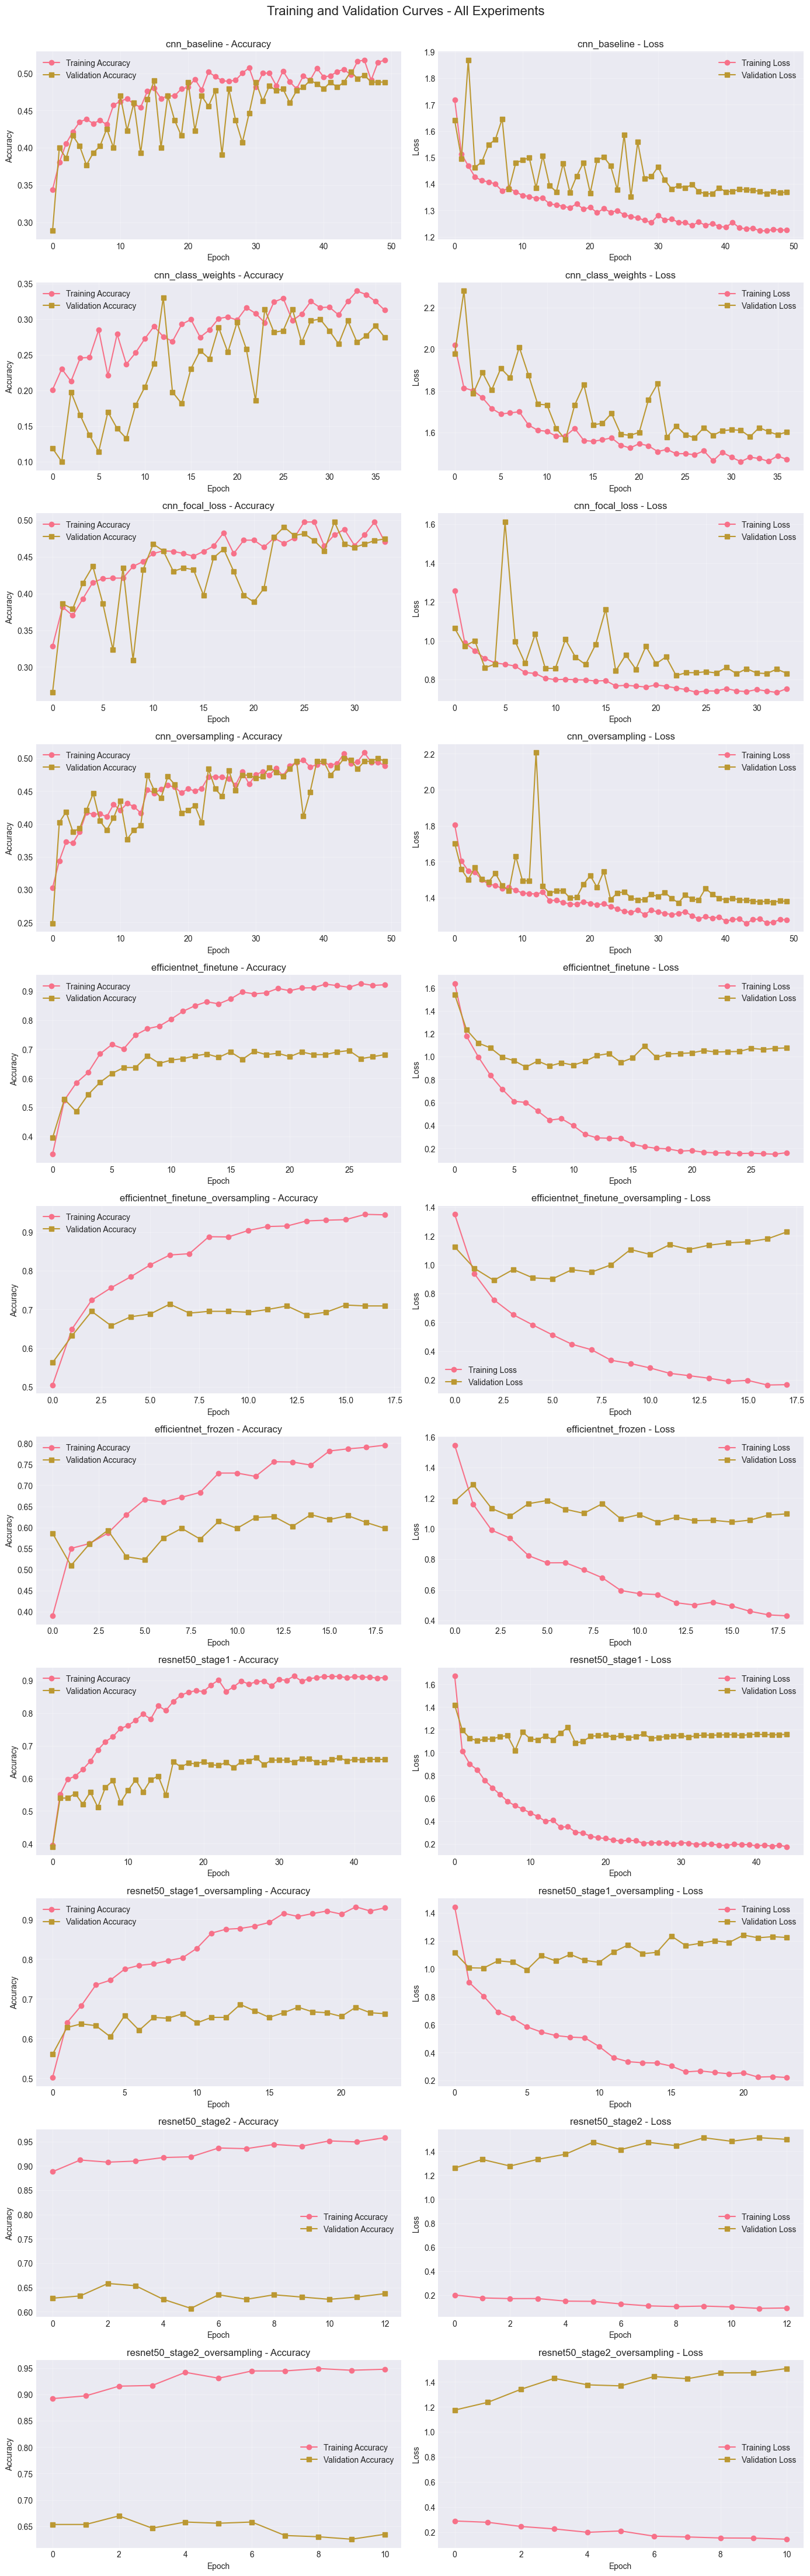

In [27]:
# ==========================================
# PLOT ACCURACY AND LOSS CURVES
# ==========================================

n = len(histories_all)

fig, axes = plt.subplots(
    n, 2,
    figsize=(14, 4 * n),
    squeeze=False
)

fig.suptitle(
    "Training and Validation Curves - All Experiments",
    fontsize=16,
    y=1.002
)

for idx, (name, hist) in enumerate(histories_all.items()):

    # Accuracy
    ax = axes[idx, 0]

    if "accuracy" in hist.columns:
        ax.plot(
            hist["accuracy"],
            "o-",
            label="Training Accuracy"
        )

    if "val_accuracy" in hist.columns:
        ax.plot(
            hist["val_accuracy"],
            "s-",
            label="Validation Accuracy"
        )

    ax.set_title(f"{name} - Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(alpha=0.3)

    # Loss
    ax = axes[idx, 1]

    if "loss" in hist.columns:
        ax.plot(
            hist["loss"],
            "o-",
            label="Training Loss"
        )

    if "val_loss" in hist.columns:
        ax.plot(
            hist["val_loss"],
            "s-",
            label="Validation Loss"
        )

    ax.set_title(f"{name} - Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

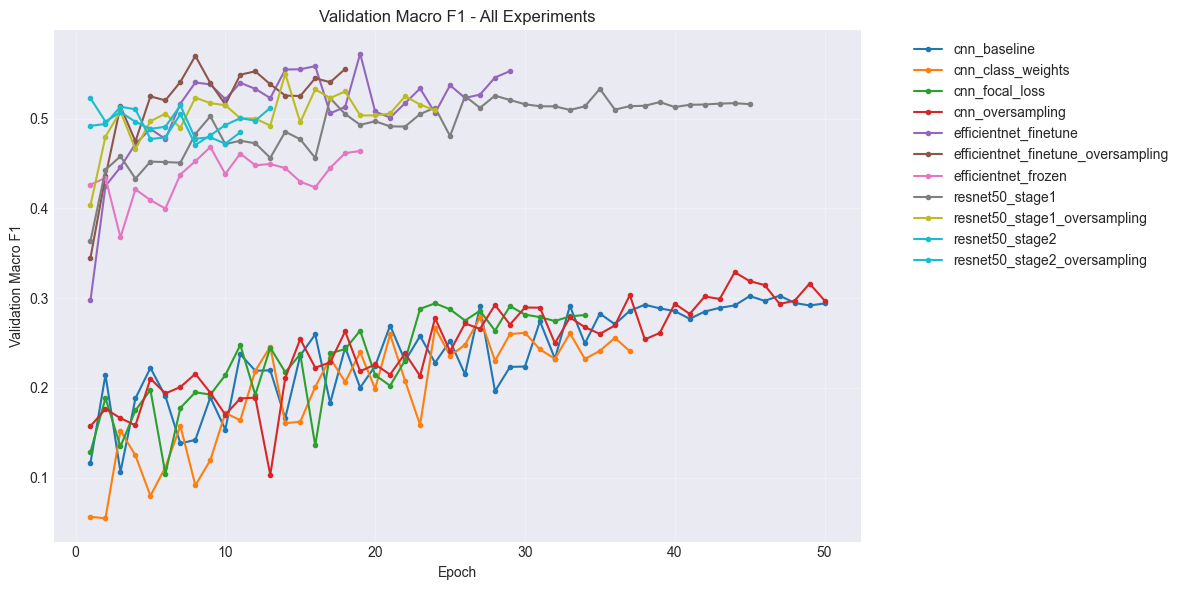

In [32]:
# ==========================================
# VALIDATION MACRO F1 CURVES
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(histories_all)))

for (name, hist), color in zip(histories_all.items(), colors):
    if "val_macro_f1" in hist.columns:
        plt.plot(
            np.arange(1, len(hist) + 1),
            hist["val_macro_f1"],
            marker="o",
            markersize=3,
            color=color,
            label=name
        )

plt.title("Validation Macro F1 - All Experiments")
plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Validation-Based Model Comparison

The trained CNN, ResNet50 and EfficientNetB0 experiments are
evaluated on the validation set.

The primary comparison metric is Macro F1-score because it gives
equal importance to all six diagnostic classes.

Additional metrics include accuracy, balanced accuracy,
precision, recall, weighted F1-score, ROC-AUC and MCC.

The best-performing configurations are shortlisted for
cross-validation.

In [33]:
# ==========================================
# CHECK AVAILABLE EXPERIMENTS AND CHECKPOINTS
# ==========================================

print("AVAILABLE TRAINING HISTORIES")
print("=" * 60)

for name, hist in histories_all.items():
    best_epoch = (
        hist["val_macro_f1"].idxmax() + 1
        if "val_macro_f1" in hist.columns else "N/A"
    )

    best_f1 = (
        hist["val_macro_f1"].max()
        if "val_macro_f1" in hist.columns else "N/A"
    )

    print(f"\n{name}")
    print(f"  Epochs recorded: {len(hist)}")
    print(f"  Best epoch: {best_epoch}")
    print(f"  Best validation Macro F1: {best_f1}")


print("\n\nAVAILABLE MODEL CHECKPOINTS")
print("=" * 60)

for file in sorted(MODEL_DIR.glob("*.weights.h5")):
    print(file.name)

AVAILABLE TRAINING HISTORIES

cnn_baseline
  Epochs recorded: 50
  Best epoch: 47
  Best validation Macro F1: 0.3027729407641457

cnn_class_weights
  Epochs recorded: 37
  Best epoch: 27
  Best validation Macro F1: 0.2784977497194569

cnn_focal_loss
  Epochs recorded: 34
  Best epoch: 24
  Best validation Macro F1: 0.2942565442006712

cnn_oversampling
  Epochs recorded: 50
  Best epoch: 44
  Best validation Macro F1: 0.3289636793091334

efficientnet_finetune
  Epochs recorded: 29
  Best epoch: 19
  Best validation Macro F1: 0.5725356419111319

efficientnet_finetune_oversampling
  Epochs recorded: 18
  Best epoch: 8
  Best validation Macro F1: 0.5700320695643628

efficientnet_frozen
  Epochs recorded: 19
  Best epoch: 9
  Best validation Macro F1: 0.4683987818999605

resnet50_stage1
  Epochs recorded: 45
  Best epoch: 35
  Best validation Macro F1: 0.5333077383763919

resnet50_stage1_oversampling
  Epochs recorded: 24
  Best epoch: 14
  Best validation Macro F1: 0.5502154520589646

resn

In [28]:
# ==========================================
# 1. LOAD BEST CHECKPOINTS AND GENERATE
#    VALIDATION PREDICTIONS
# ==========================================

import gc
import numpy as np
import tensorflow as tf

# ------------------------------------------
# Ground-truth validation labels
# ------------------------------------------

# val_ds is not shuffled, so this order matches model.predict(val_ds).
y_val = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

# ------------------------------------------
# Define all experiments
# ------------------------------------------

cnn_experiments = [
    "cnn_baseline",
    "cnn_class_weights",
    "cnn_focal_loss",
    "cnn_oversampling"
]

resnet_experiments = [
    "resnet50_stage1",
    "resnet50_stage1_oversampling",
    "resnet50_stage2",
    "resnet50_stage2_oversampling"
]

efficientnet_experiments = [
    "efficientnet_frozen",
    "efficientnet_finetune",
    "efficientnet_finetune_oversampling"

]

all_experiments = (
    cnn_experiments
    + resnet_experiments
    + efficientnet_experiments
)

# Check all checkpoint files exist before evaluating
missing_checkpoints = [
    name for name in all_experiments
    if not (MODEL_DIR / f"{name}_best.weights.h5").is_file()
]

if missing_checkpoints:
    raise FileNotFoundError(
        f"Missing best checkpoints: {missing_checkpoints}"
    )

print("All checkpoint files found.")

# Store predictions
val_predictions = {}


# ==========================================
# CNN EXPERIMENTS
# ==========================================

for name in cnn_experiments:

    checkpoint = MODEL_DIR / f"{name}_best.weights.h5"

    keras.backend.clear_session()

    model = create_simple_cnn(
        lr=0.001,
        dropout=0.4,
        use_focal=(name == "cnn_focal_loss"),
        use_augmentation=True,
        use_bn=True
    )

    model.load_weights(checkpoint)

    print(f"\nEvaluating {name}")

    probabilities = model.predict(val_ds, verbose=0)

    val_predictions[name] = probabilities

    print("Prediction shape:", probabilities.shape)

    del model
    keras.backend.clear_session()
    gc.collect()


# ==========================================
# RESNET50 EXPERIMENTS
# ==========================================

for name in resnet_experiments:

    checkpoint = MODEL_DIR / f"{name}_best.weights.h5"

    keras.backend.clear_session()

    # The architecture and weight shapes are identical
    # regardless of the fine-tuning configuration.
    model, base = create_resnet(
        fine_tune=False,
        lr=0.0001
    )

    model.load_weights(checkpoint)

    print(f"\nEvaluating {name}")

    probabilities = model.predict(val_ds, verbose=0)

    val_predictions[name] = probabilities

    print("Prediction shape:", probabilities.shape)

    del model, base
    keras.backend.clear_session()
    gc.collect()


# ==========================================
# EFFICIENTNETB0 EXPERIMENTS
# ==========================================

for name in efficientnet_experiments:

    checkpoint = MODEL_DIR / f"{name}_best.weights.h5"

    keras.backend.clear_session()

    # Trainability does not change the model's weight shapes.
    # A frozen backbone is sufficient for inference.
    model, base = create_efficientnet(
        fine_tune=False,
        lr=0.0001
    )

    model.load_weights(checkpoint)

    print(f"\nEvaluating {name}")

    probabilities = model.predict(val_ds, verbose=0)

    val_predictions[name] = probabilities

    print("Prediction shape:", probabilities.shape)

    del model, base
    keras.backend.clear_session()
    gc.collect()


# ==========================================
# VERIFY ALL PREDICTIONS
# ==========================================

print("\n" + "=" * 60)
print("VALIDATION PREDICTIONS COMPLETE")
print("=" * 60)

print("Number of experiments:", len(val_predictions))
print("Number of validation samples:", len(y_val))



for name, probabilities in val_predictions.items():

    assert probabilities.shape == (
        len(y_val), NUM_CLASSES
    ), f"Incorrect prediction shape for {name}"

    assert np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-4
    ), f"Invalid probability outputs for {name}"

    print(f"{name:35s} {probabilities.shape}")

print("\nAll prediction checks passed.")

All checkpoint files found.



C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(store)



Evaluating cnn_baseline
Prediction shape: (430, 6)

Evaluating cnn_class_weights
Prediction shape: (430, 6)

Evaluating cnn_focal_loss
Prediction shape: (430, 6)

Evaluating cnn_oversampling
Prediction shape: (430, 6)
Trainable parameters: 526,086


C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)



Evaluating resnet50_stage1
Prediction shape: (430, 6)
Trainable parameters: 526,086

Evaluating resnet50_stage1_oversampling
Prediction shape: (430, 6)
Trainable parameters: 526,086


C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(store)



Evaluating resnet50_stage2
Prediction shape: (430, 6)
Trainable parameters: 526,086

Evaluating resnet50_stage2_oversampling
Prediction shape: (430, 6)
Trainable parameters: 329,478
Total parameters: 4,379,049.0

Evaluating efficientnet_frozen
Prediction shape: (430, 6)
Trainable parameters: 329,478
Total parameters: 4,379,049.0


C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 82 variables. 
  saveable.load_own_variables(store)



Evaluating efficientnet_finetune
Prediction shape: (430, 6)
Trainable parameters: 329,478
Total parameters: 4,379,049.0

Evaluating efficientnet_finetune_oversampling
Prediction shape: (430, 6)

VALIDATION PREDICTIONS COMPLETE
Number of experiments: 11
Number of validation samples: 430
cnn_baseline                        (430, 6)
cnn_class_weights                   (430, 6)
cnn_focal_loss                      (430, 6)
cnn_oversampling                    (430, 6)
resnet50_stage1                     (430, 6)
resnet50_stage1_oversampling        (430, 6)
resnet50_stage2                     (430, 6)
resnet50_stage2_oversampling        (430, 6)
efficientnet_frozen                 (430, 6)
efficientnet_finetune               (430, 6)
efficientnet_finetune_oversampling  (430, 6)

All prediction checks passed.


In [29]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss
)

from sklearn.preprocessing import label_binarize

# Ensure labels are NumPy arrays
y_val = np.asarray(y_val).astype(int)

# One-hot encoded labels
y_val_binary = label_binarize(
    y_val,
    classes=np.arange(NUM_CLASSES)
)

comparison_results = []
per_class_results = []
confusion_matrices = {}

for name, probabilities in val_predictions.items():

    print(f"Calculating metrics: {name}")

    probabilities = np.asarray(probabilities)

    # Predicted classes
    y_pred = np.argmax(probabilities, axis=1)

    # Confusion matrix
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )
    confusion_matrices[name] = cm

    # Classification metrics
    accuracy = accuracy_score(y_val, y_pred)

    balanced_acc = balanced_accuracy_score(y_val, y_pred)

    macro_precision = precision_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    macro_recall = recall_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    weighted_f1 = f1_score(
        y_val, y_pred, average="weighted", zero_division=0
    )

    # Probability-based metrics
    macro_roc_auc = roc_auc_score(
        y_val,
        probabilities,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro"
    )

    macro_ap = average_precision_score(
        y_val_binary,
        probabilities,
        average="macro"
    )

    # Additional classification metrics
    mcc = matthews_corrcoef(y_val, y_pred)

    cross_entropy = log_loss(
        y_val,
        probabilities,
        labels=np.arange(NUM_CLASSES)
    )

    # Multiclass Brier score
    brier_score = np.mean(
        np.sum(
            (probabilities - y_val_binary) ** 2,
            axis=1
        )
    )

    # Store overall results
    comparison_results.append({
        "Experiment": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Macro ROC-AUC": macro_roc_auc,
        "Macro Average Precision": macro_ap,
        "MCC": mcc,
        "Log Loss": cross_entropy,
        "Brier Score": brier_score
    })

    # Per-class metrics
    report = classification_report(
        y_val,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )

    for i, class_name in enumerate(CLASSES):

        true_binary = y_val_binary[:, i]
        class_probs = probabilities[:, i]

        class_auc = roc_auc_score(
            true_binary, class_probs
        )

        class_ap = average_precision_score(
            true_binary, class_probs
        )

        per_class_results.append({
            "Experiment": name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"],
            "ROC-AUC": class_auc,
            "Average Precision": class_ap
        })


# Create DataFrames
comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

per_class_df = pd.DataFrame(per_class_results)

print("\nVALIDATION METRICS CALCULATED FOR ALL MODELS.")


Calculating metrics: cnn_baseline
Calculating metrics: cnn_class_weights
Calculating metrics: cnn_focal_loss
Calculating metrics: cnn_oversampling
Calculating metrics: resnet50_stage1
Calculating metrics: resnet50_stage1_oversampling
Calculating metrics: resnet50_stage2
Calculating metrics: resnet50_stage2_oversampling
Calculating metrics: efficientnet_frozen
Calculating metrics: efficientnet_finetune
Calculating metrics: efficientnet_finetune_oversampling

VALIDATION METRICS CALCULATED FOR ALL MODELS.


In [30]:
# Metrics to display
display_columns = [
    "Experiment",
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Macro ROC-AUC",
    "Macro Average Precision",
    "MCC",
    "Log Loss",
    "Brier Score"
]

display(
    comparison_df[display_columns].style.format({
        col: "{:.4f}"
        for col in display_columns
        if col != "Experiment"
    })
)

,Experiment,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,Macro Average Precision,MCC,Log Loss,Brier Score
0,efficientnet_finetune,0.6814,0.5825,0.5845,0.5825,0.5725,0.6797,0.8914,0.5979,0.5634,1.0236,0.4695
1,efficientnet_finetune_oversampling,0.6907,0.5803,0.5664,0.5803,0.5700,0.6864,0.8774,0.5853,0.5794,0.9486,0.4489
2,resnet50_stage1_oversampling,0.6860,0.5408,0.5841,0.5408,0.5502,0.6604,0.8628,0.5722,0.5588,1.1075,0.4813
3,resnet50_stage1,0.6605,0.5356,0.5434,0.5356,0.5333,0.6411,0.8505,0.5468,0.5269,1.1527,0.5166
4,resnet50_stage2_oversampling,0.6535,0.5208,0.5407,0.5208,0.5229,0.6314,0.8586,0.5753,0.5139,1.1742,0.5024
5,resnet50_stage2,0.6581,0.5171,0.5178,0.5171,0.5135,0.6406,0.8459,0.5290,0.5252,1.2763,0.5254
6,efficientnet_frozen,0.5721,0.4695,0.4942,0.4695,0.4684,0.5870,0.8330,0.4828,0.4272,1.1625,0.5803
7,cnn_oversampling,0.5000,0.3391,0.3461,0.3391,0.3290,0.4662,0.6775,0.3109,0.2886,1.3884,0.6749
8,cnn_baseline,0.4977,0.3240,0.3309,0.3240,0.3028,0.4542,0.6787,0.3187,0.2787,1.3631,0.6654
9,cnn_focal_loss,0.4907,0.3122,0.3103,0.3122,0.2943,0.4515,0.6719,0.2957,0.2711,1.3864,0.6881


In [31]:
for name in comparison_df["Experiment"]:

    print("\n" + "=" * 85)
    print(f"PER-CLASS VALIDATION METRICS: {name}")
    print("=" * 85)

    display(
        per_class_df[
            per_class_df["Experiment"] == name
        ].drop(columns="Experiment").set_index("Class").round(4)
    )


PER-CLASS VALIDATION METRICS: efficientnet_finetune


,Precision,Recall,F1-score,Support,ROC-AUC,Average Precision
Class,,,,,,
ACK,0.7372,0.7769,0.7566,130.0,0.9103,0.8452
BCC,0.7278,0.7500,0.7387,164.0,0.8965,0.8059
MEL,0.3333,0.5000,0.4000,8.0,0.9274,0.2074
NEV,0.6458,0.7561,0.6966,41.0,0.9535,0.7167
SCC,0.2188,0.2121,0.2154,33.0,0.7178,0.2248
SEK,0.8438,0.5000,0.6279,54.0,0.9426,0.7872



PER-CLASS VALIDATION METRICS: efficientnet_finetune_oversampling


,Precision,Recall,F1-score,Support,ROC-AUC,Average Precision
Class,,,,,,
ACK,0.6980,0.8000,0.7455,130.0,0.9151,0.8368
BCC,0.7785,0.7073,0.7412,164.0,0.9057,0.8170
MEL,0.2727,0.3750,0.3158,8.0,0.9073,0.1952
NEV,0.6923,0.6585,0.6750,41.0,0.9455,0.7215
SCC,0.2500,0.1818,0.2105,33.0,0.6697,0.1721
SEK,0.7069,0.7593,0.7321,54.0,0.9210,0.7689



PER-CLASS VALIDATION METRICS: resnet50_stage1_oversampling


,Precision,Recall,F1-score,Support,ROC-AUC,Average Precision
Class,,,,,,
ACK,0.7042,0.7692,0.7353,130.0,0.8988,0.8111
BCC,0.6935,0.8415,0.7603,164.0,0.8820,0.7968
MEL,0.5714,0.5000,0.5333,8.0,0.9218,0.3483
NEV,0.6857,0.5854,0.6316,41.0,0.9592,0.7390
SCC,0.1667,0.0303,0.0513,33.0,0.6358,0.1114
SEK,0.6829,0.5185,0.5895,54.0,0.8793,0.6267


... (12 outputs left out)


PER-CLASS VALIDATION METRICS: cnn_focal_loss


,Precision,Recall,F1-score,Support,ROC-AUC,Average Precision
Class,,,,,,
ACK,0.4691,0.5846,0.5205,130.0,0.6198,0.4014
BCC,0.5377,0.6524,0.5895,164.0,0.7275,0.5850
MEL,0.0000,0.0000,0.0000,8.0,0.6751,0.0986
NEV,0.3846,0.4878,0.4301,41.0,0.8031,0.3181
SCC,0.0000,0.0000,0.0000,33.0,0.4635,0.0725
SEK,0.4706,0.1481,0.2254,54.0,0.7425,0.2982



PER-CLASS VALIDATION METRICS: cnn_class_weights


,Precision,Recall,F1-score,Support,ROC-AUC,Average Precision
Class,,,,,,
ACK,0.4795,0.2692,0.3448,130.0,0.6292,0.4358
BCC,0.5402,0.2866,0.3745,164.0,0.7129,0.5597
MEL,0.0714,0.2500,0.1111,8.0,0.6949,0.0974
NEV,0.2963,0.3902,0.3368,41.0,0.7731,0.3425
SCC,0.0686,0.2121,0.1037,33.0,0.4443,0.0694
SEK,0.3256,0.5185,0.4000,54.0,0.7449,0.3133


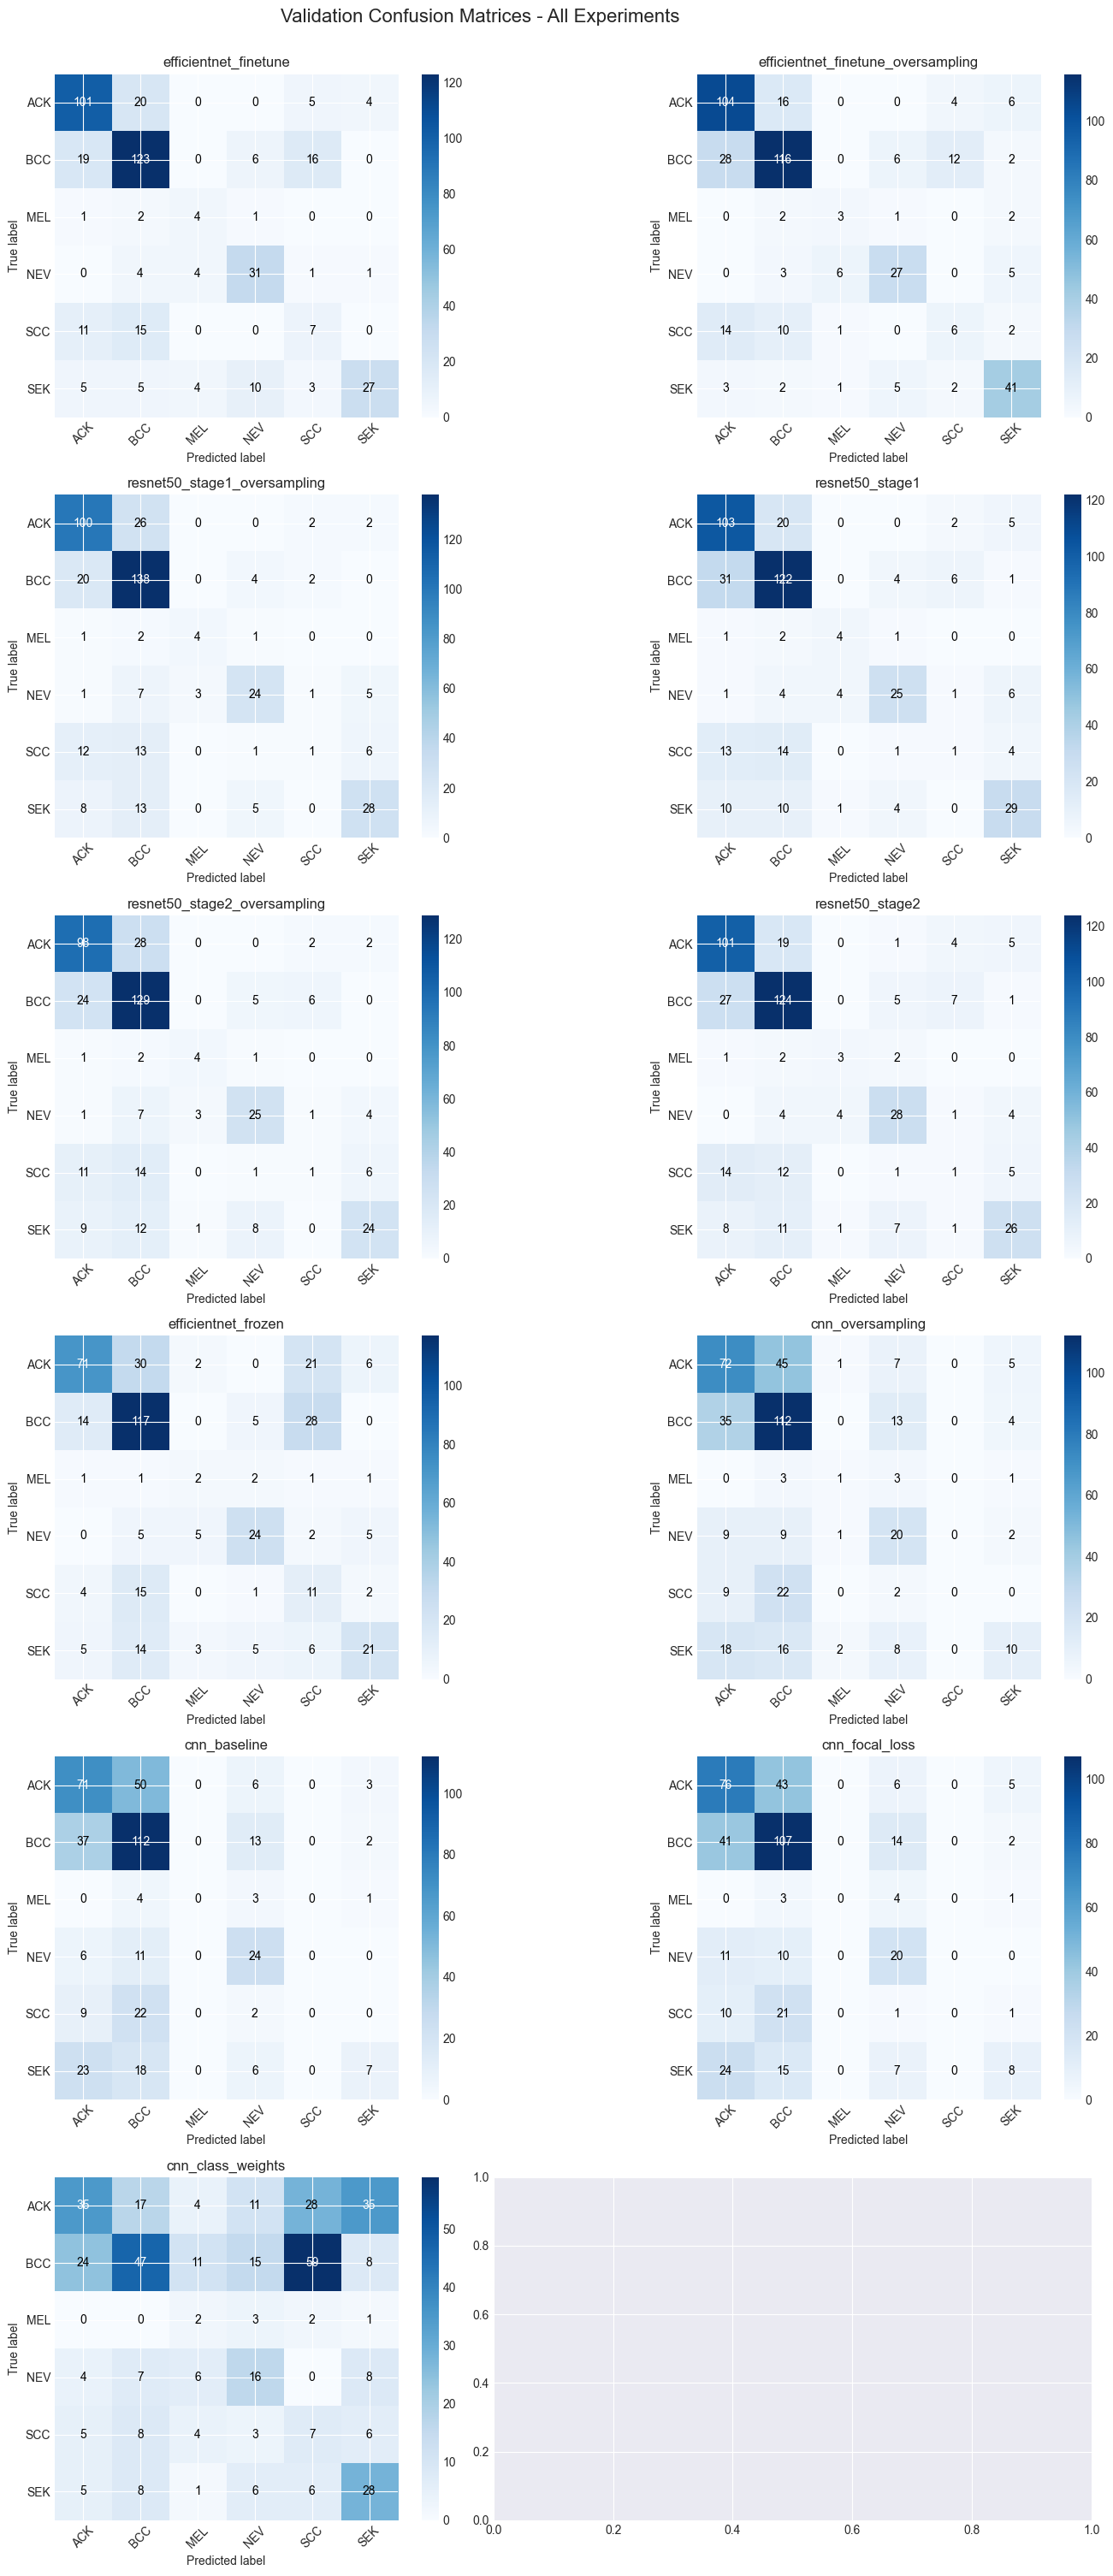

In [32]:
fig, axes = plt.subplots(6, 2, figsize=(15, 30))

for ax, name in zip(axes.flat, comparison_df["Experiment"]):

    cm = confusion_matrices[name]

    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    ax.set_xticks(np.arange(NUM_CLASSES))
    ax.set_yticks(np.arange(NUM_CLASSES))

    ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticklabels(CLASSES)

    threshold = cm.max() / 2

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                color="white" if cm[i, j] > threshold else "black"
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(
    "Validation Confusion Matrices - All Experiments",
    fontsize=16,
    y=1.002
)

plt.tight_layout()
plt.show()

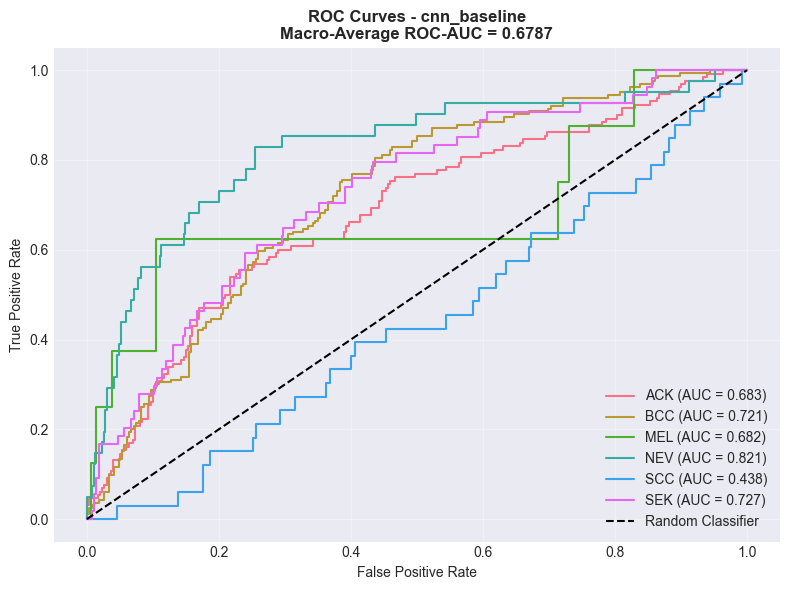

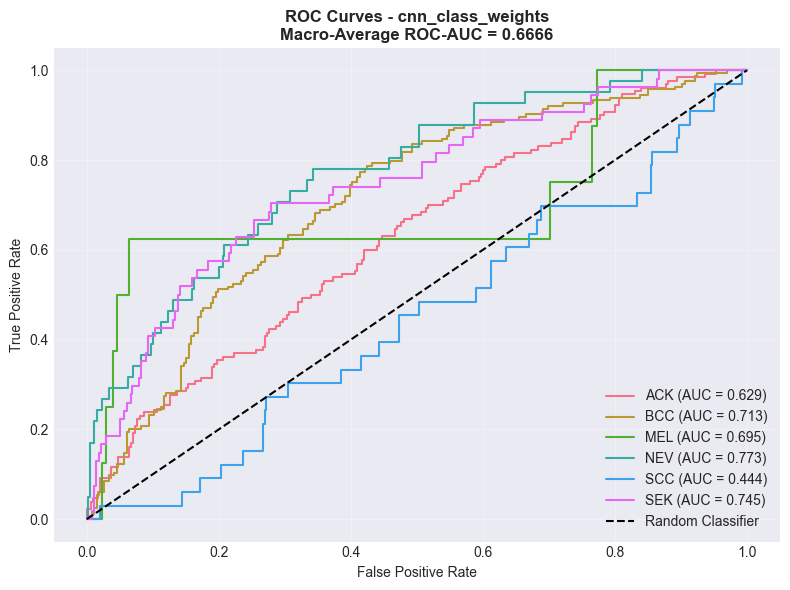

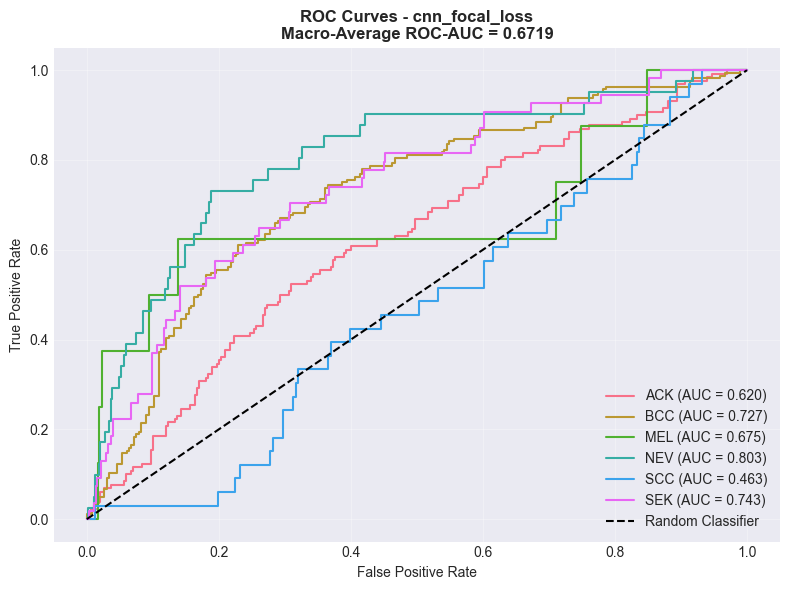

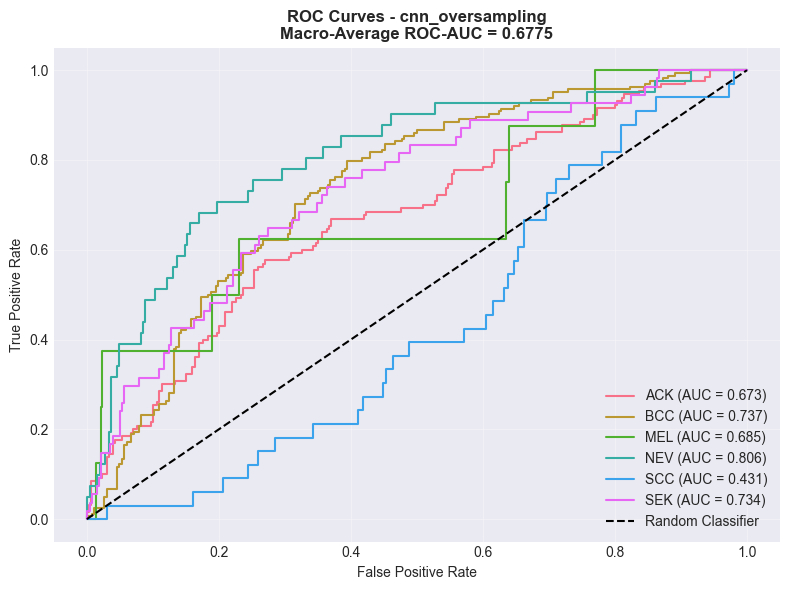

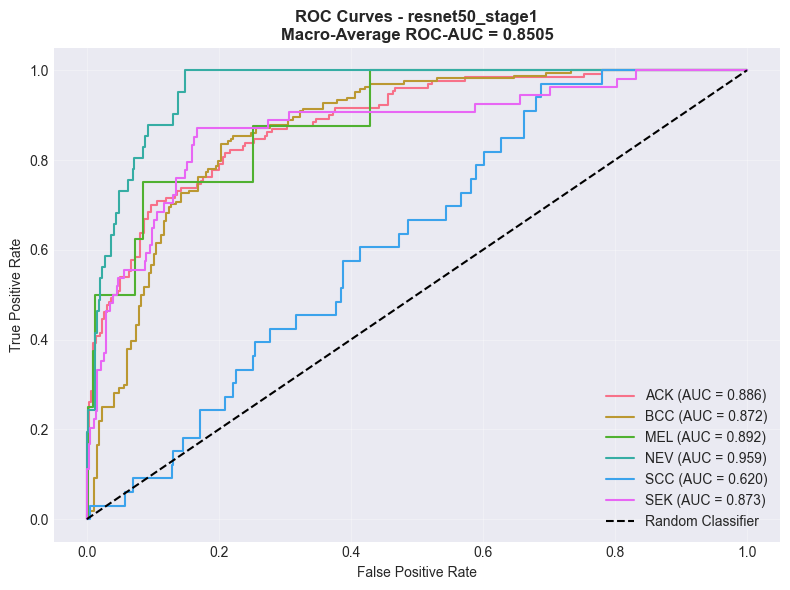

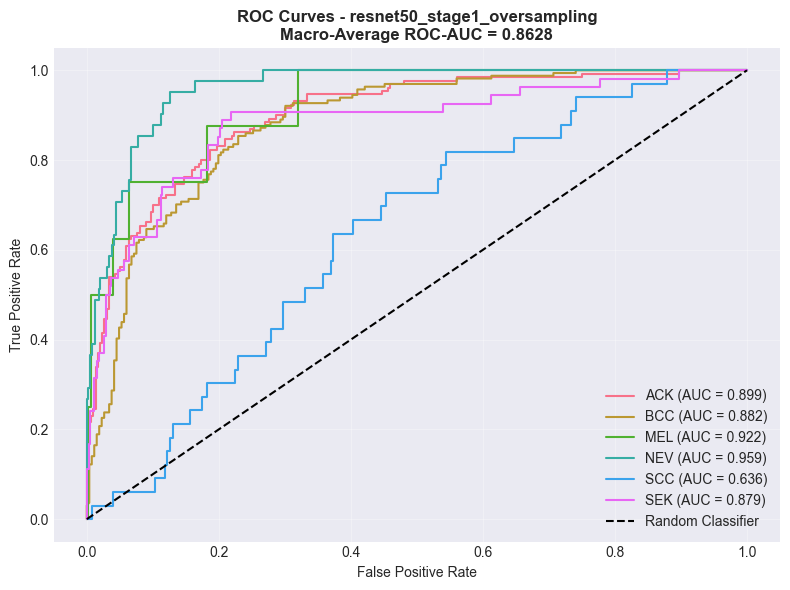

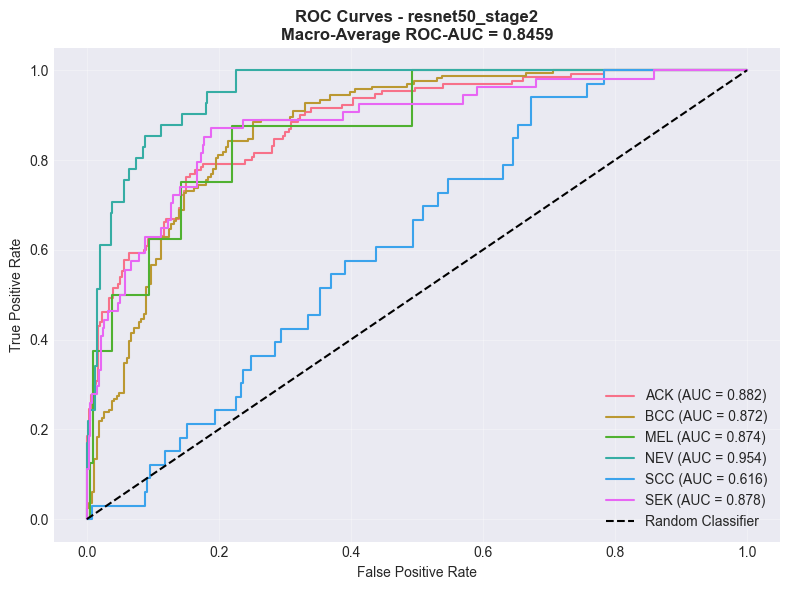

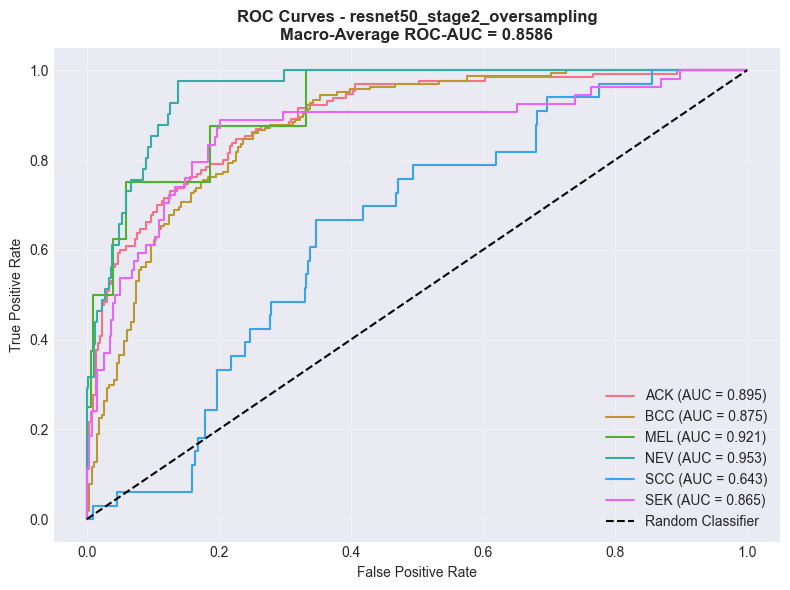

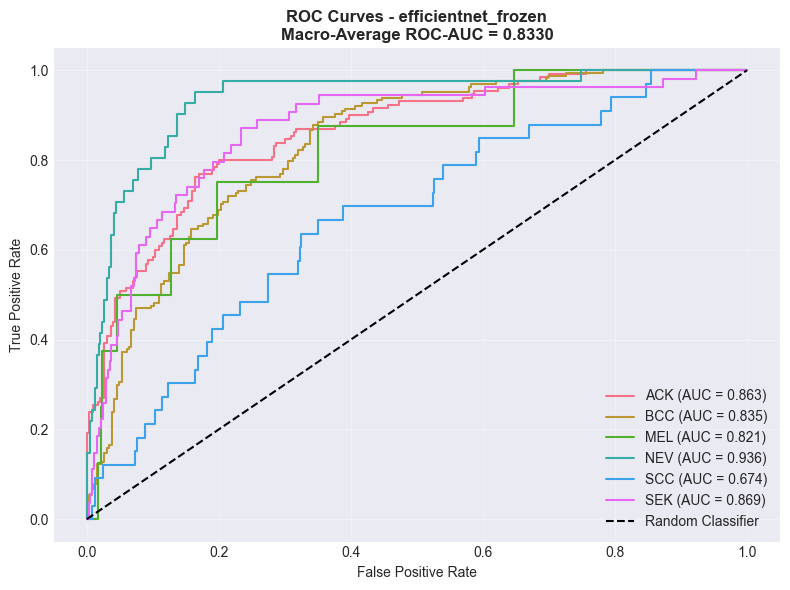

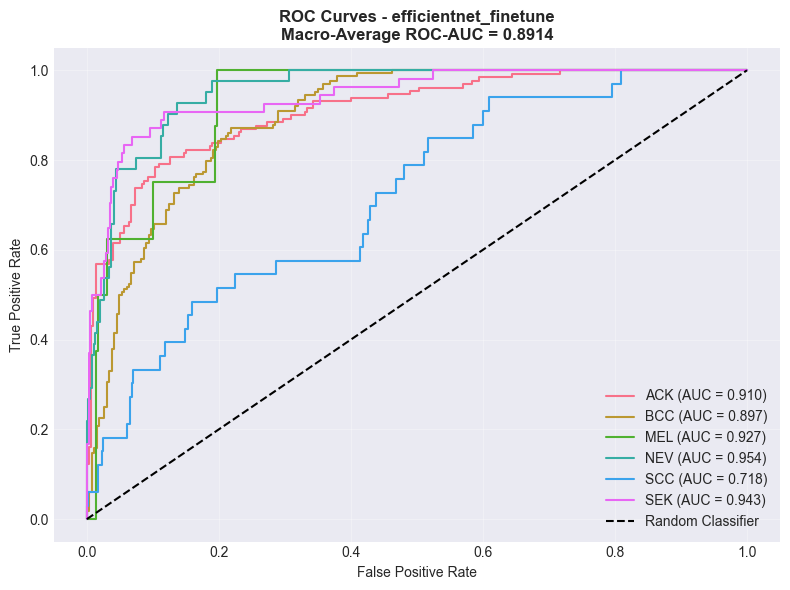

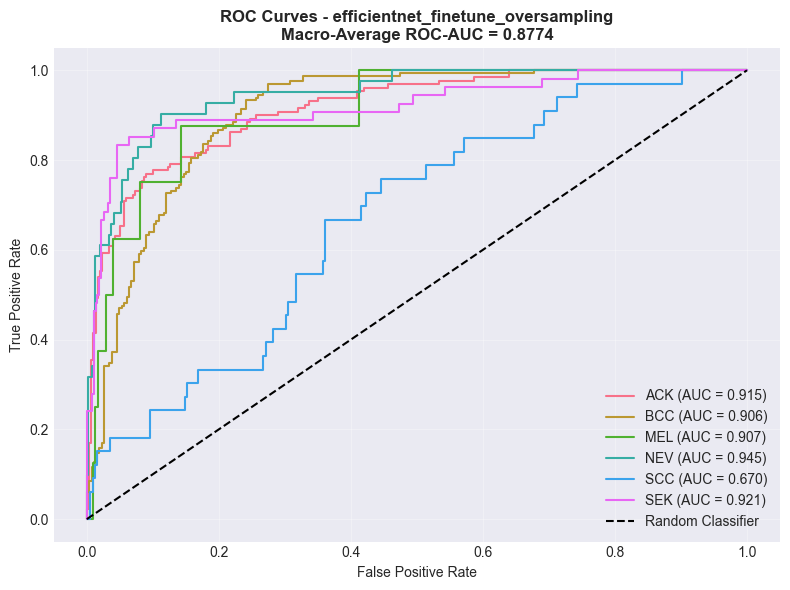

In [34]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# One-hot encode validation labels
y_val_binary = label_binarize(
    y_val,
    classes=np.arange(NUM_CLASSES)
)

# Plot ROC curves for each experiment
for name, probabilities in val_predictions.items():

    plt.figure(figsize=(8, 6))

    class_aucs = []

    # Individual class ROC curves
    for i, class_name in enumerate(CLASSES):

        fpr, tpr, _ = roc_curve(
            y_val_binary[:, i],
            probabilities[:, i]
        )

        class_auc = auc(fpr, tpr)
        class_aucs.append(class_auc)

        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC = {class_auc:.3f})"
        )

    # Macro-average ROC-AUC
    macro_auc = np.mean(class_aucs)

    # Random classifier reference
    plt.plot(
        [0, 1], [0, 1],
        "k--",
        label="Random Classifier"
    )

    plt.title(
        f"ROC Curves - {name}\nMacro-Average ROC-AUC = {macro_auc:.4f}",
        fontsize=12,
        fontweight="bold"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## 10. Patient-Level Cross-Validation

The three best configurations from the initial validation comparison
are evaluated using four-fold cross-validation on development
folds 1–4.

For each round, three folds are used for training and one fold
is used for validation.

A fresh model is initialised for every fold. Class weights and
oversampling are recalculated using the corresponding training
fold only.

The held-out test fold (fold 0) is excluded from this process.

Mean and standard deviation of the evaluation metrics are
calculated across the four folds.

In [35]:

#CROSS-VALIDATION CONFIGURATION


import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score,
    classification_report, confusion_matrix
)

FINAL_TEST_FOLD = 0
DEV_FOLDS = [1, 2, 3, 4]
CV_EPOCHS = 50

CV_RESULT_DIR = RESULT_DIR / "cross_validation"
CV_RESULT_DIR.mkdir(parents=True, exist_ok=True)

In [36]:

# HELPER FUNCTIONS


def get_fold_indices(val_fold):
    folds = df["fold"].to_numpy()
    train_idx = np.where(np.isin(folds, [f for f in DEV_FOLDS if f != val_fold]))[0]
    val_idx = np.where(folds == val_fold)[0]

    train_patients = set(df.iloc[train_idx]["patient_id"])
    val_patients = set(df.iloc[val_idx]["patient_id"])
    assert train_patients.isdisjoint(val_patients), "Patient leakage detected!"

    return train_idx, val_idx


def get_class_weights(indices):
    labels = y[indices]
    classes = np.unique(labels)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=labels
    )

    return {int(c): float(w) for c, w in zip(classes, weights)}


def oversample_indices(indices, seed=SEED):
    rng = np.random.default_rng(seed)
    labels = y[indices]
    target = int(np.ceil(np.median(np.bincount(
        labels, minlength=NUM_CLASSES
    ))))

    sampled = []

    for cls in range(NUM_CLASSES):
        cls_idx = indices[labels == cls]

        if len(cls_idx) == 0:
            raise ValueError(f"Class {CLASSES[cls]} is missing from training data.")

        if len(cls_idx) < target:
            extra = rng.choice(
                cls_idx, target - len(cls_idx), replace=True
            )
            cls_idx = np.concatenate([cls_idx, extra])

        sampled.extend(cls_idx)

    result = np.asarray(sampled, dtype=np.int32)
    rng.shuffle(result)
    return result


def evaluate_predictions(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)

    try:
        auc = roc_auc_score(
            y_true, probabilities,
            multi_class="ovr", average="macro",
            labels=np.arange(NUM_CLASSES)
        )
    except ValueError:
        auc = np.nan

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(y_true, predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, predictions, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, predictions, average="weighted", zero_division=0),
        "Macro ROC-AUC": auc,
        "MCC": matthews_corrcoef(y_true, predictions)
    }

In [37]:

# MODEL CONFIGURATIONS


CV_MODELS = {
    "efficientnet_finetune": {
        "architecture": "EfficientNetB0",
        "lr": 0.0001,
        "strategy": "class_weights"
    },

    "efficientnet_finetune_oversampling": {
        "architecture": "EfficientNetB0",
        "lr": 0.0001,
        "strategy": "oversampling"
    },

    "resnet50_stage1_oversampling": {
        "architecture": "ResNet50",
        "lr": 0.001,
        "strategy": "oversampling"
    }
}


def build_cv_model(name):
    config = CV_MODELS[name]

    if config["architecture"] == "EfficientNetB0":
        return create_efficientnet(
            fine_tune=True,
            lr=config["lr"]
        )

    return create_resnet(
        fine_tune=False,
        lr=config["lr"]
    )

In [38]:

# CROSS-VALIDATION TRAINING


def run_cross_validation(model_name):

    config = CV_MODELS[model_name]
    fold_results, fold_predictions = [], {}

    for val_fold in DEV_FOLDS:

        print(f"\n{'='*60}\n{model_name} | Validation fold {val_fold}\n{'='*60}")

        tf.keras.utils.set_random_seed(SEED + val_fold)
        train_idx, val_idx = get_fold_indices(val_fold)

        # Apply the experiment's imbalance strategy
        class_weight = None

        if config["strategy"] == "oversampling":
            train_idx_used = oversample_indices(train_idx, SEED + val_fold)
        else:
            train_idx_used = train_idx
            class_weight = get_class_weights(train_idx)

        train_data = make_ds(train_idx_used, training=True)
        val_data = make_ds(val_idx, training=False)

        # Fresh model for every fold
        model, _ = build_cv_model(model_name)

        run_name = f"cv_{model_name}_fold_{val_fold}"
        callbacks = get_callbacks(run_name, val_data=val_data)

        history = model.fit(
            train_data,
            validation_data=val_data,
            epochs=CV_EPOCHS,
            class_weight=class_weight,
            callbacks=callbacks,
            verbose=1
        )

        # Best epoch and validation predictions
        best_epoch = int(np.argmax(history.history["val_macro_f1"]) + 1)
        probabilities = model.predict(val_data, verbose=0)
        metrics = evaluate_predictions(y[val_idx], probabilities)

        fold_results.append({
            "Model": model_name,
            "Fold": val_fold,
            "Best Epoch": best_epoch,
            **metrics
        })

        fold_predictions[val_fold] = {
            "indices": val_idx,
            "probabilities": probabilities
        }

        pd.DataFrame(history.history).to_csv(
            CV_RESULT_DIR / f"{run_name}_history.csv", index=False
        )

        np.savez(
            CV_RESULT_DIR / f"{run_name}_predictions.npz",
            indices=val_idx,
            probabilities=probabilities
        )

        print(f"Best epoch: {best_epoch} | Macro F1: {metrics['Macro F1']:.4f}")

        del model, train_data, val_data
        tf.keras.backend.clear_session()
        gc.collect()

    return pd.DataFrame(fold_results), fold_predictions

In [ ]:
# ============================================================
# 5. RUN ALL CROSS-VALIDATION EXPERIMENTS
# ============================================================

all_cv_results = []
all_cv_predictions = {}

for name in CV_MODELS:
    cv_fold_results, predictions = run_cross_validation(name)

    all_cv_results.append(cv_fold_results)
    all_cv_predictions[name] = predictions

cv_results_df = pd.concat(all_cv_results, ignore_index=True)

cv_results_df.to_csv(
    CV_RESULT_DIR / "all_cv_fold_results.csv", index=False
)

display(cv_results_df)


efficientnet_finetune | Validation fold 1
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 3,459,362
Total parameters: 4,379,049.0
Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.2764 - loss: 1.7745 - val_macro_f1: 0.3211
43/43 ━━━━━━━━━━━━━━━━━━━━ 37s 391ms/step - accuracy: 0.3525 - loss: 1.6764 - val_accuracy: 0.3930 - val_loss: 1.4351 - val_macro_f1: 0.3211 - learning_rate: 1.0000e-04
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.4862 - loss: 1.2713 - val_macro_f1: 0.3974
43/43 ━━━━━━━━━━━━━━━━━━━━ 14s 320ms/step - accuracy: 0.5113 - loss: 1.2093 - val_accuracy: 0.5581 - val_loss: 1.1718 - val_macro_f1: 0.3974 - learning_rate: 1.0000e-04
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5653 - loss: 1.0206 - val_macro_f1: 0.4528
43/43 ━━━━━━━━━━━━━━━━━━━━ 12s 272ms/step - accuracy: 0.5783 - loss: 0.9769 - val_accuracy: 0.6302 - val_loss: 1.0271 - val_macro_f1: 0.4528 - learning_rate: 1.0000e-04
Epoch 4/50
43

,Model,Fold,Best Epoch,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,MCC
0,efficientnet_finetune,1,19,0.711628,0.565111,0.583269,0.565111,0.567324,0.700053,0.881407,0.599908
1,efficientnet_finetune,2,11,0.741722,0.644006,0.688711,0.644006,0.650462,0.739732,0.903474,0.650707
2,efficientnet_finetune,3,26,0.694505,0.630072,0.638187,0.630072,0.632600,0.688536,0.894433,0.572428
3,efficientnet_finetune,4,11,0.670968,0.622383,0.670931,0.622383,0.634797,0.682732,0.910195,0.568216
4,efficientnet_finetune_oversampling,1,7,0.700000,0.549938,0.575596,0.549938,0.556151,0.694326,0.878928,0.585855
5,efficientnet_finetune_oversampling,2,11,0.728477,0.594760,0.666036,0.594760,0.612135,0.714972,0.899298,0.625009
6,efficientnet_finetune_oversampling,3,5,0.709890,0.606054,0.652442,0.606054,0.621342,0.691140,0.888428,0.589307
7,efficientnet_finetune_oversampling,4,9,0.707527,0.589768,0.718503,0.589768,0.624123,0.699974,0.912617,0.598258
8,resnet50_stage1_oversampling,1,8,0.667442,0.534662,0.559163,0.534662,0.540286,0.655578,0.861235,0.540854
9,resnet50_stage1_oversampling,2,5,0.688742,0.537727,0.666318,0.537727,0.563613,0.670660,0.881752,0.566857


In [39]:
# Check CSV files saved in your CV results folder

print("CV_RESULT_DIR:", CV_RESULT_DIR)

for file in sorted(CV_RESULT_DIR.glob("*.csv")):
    print(file.name)

CV_RESULT_DIR: skin_lesion_artifacts\results\cross_validation
all_cv_fold_results.csv
cv_efficientnet_finetune_fold_1_history.csv
cv_efficientnet_finetune_fold_2_history.csv
cv_efficientnet_finetune_fold_3_history.csv
cv_efficientnet_finetune_fold_4_history.csv
cv_efficientnet_finetune_oversampling_fold_1_history.csv
cv_efficientnet_finetune_oversampling_fold_2_history.csv
cv_efficientnet_finetune_oversampling_fold_3_history.csv
cv_efficientnet_finetune_oversampling_fold_4_history.csv
cv_model_comparison.csv
cv_resnet50_stage1_oversampling_fold_1_history.csv
cv_resnet50_stage1_oversampling_fold_2_history.csv
cv_resnet50_stage1_oversampling_fold_3_history.csv
cv_resnet50_stage1_oversampling_fold_4_history.csv
final_test_metrics.csv
final_test_predictions.csv
final_training_history.csv
per_class_test_metrics.csv


In [40]:
# Reload saved cross-validation results

cv_results_df = pd.read_csv(
    CV_RESULT_DIR / "all_cv_fold_results.csv"
)

print("CV results loaded successfully.")
print("Shape:", cv_results_df.shape)

display(cv_results_df)

CV results loaded successfully.
Shape: (12, 11)


,Model,Fold,Best Epoch,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,MCC
0,efficientnet_finetune,1,19,0.711628,0.565111,0.583269,0.565111,0.567324,0.700053,0.881407,0.599908
1,efficientnet_finetune,2,11,0.741722,0.644006,0.688711,0.644006,0.650462,0.739732,0.903474,0.650707
2,efficientnet_finetune,3,26,0.694505,0.630072,0.638187,0.630072,0.632600,0.688536,0.894433,0.572428
3,efficientnet_finetune,4,11,0.670968,0.622383,0.670931,0.622383,0.634797,0.682732,0.910195,0.568216
4,efficientnet_finetune_oversampling,1,7,0.700000,0.549938,0.575596,0.549938,0.556151,0.694326,0.878928,0.585855
5,efficientnet_finetune_oversampling,2,11,0.728477,0.594760,0.666036,0.594760,0.612135,0.714972,0.899298,0.625009
6,efficientnet_finetune_oversampling,3,5,0.709890,0.606054,0.652442,0.606054,0.621342,0.691140,0.888428,0.589307
7,efficientnet_finetune_oversampling,4,9,0.707527,0.589768,0.718503,0.589768,0.624123,0.699974,0.912617,0.598258
8,resnet50_stage1_oversampling,1,8,0.667442,0.534662,0.559163,0.534662,0.540286,0.655578,0.861235,0.540854
9,resnet50_stage1_oversampling,2,5,0.688742,0.537727,0.666318,0.537727,0.563613,0.670660,0.881752,0.566857


In [41]:
# ============================================================
# 6. CROSS-VALIDATION COMPARISON
# ============================================================

metrics = [
    "Accuracy", "Balanced Accuracy",
    "Macro Precision", "Macro Recall",
    "Macro F1", "Weighted F1",
    "Macro ROC-AUC", "MCC"
]

cv_summary = cv_results_df.groupby("Model")[metrics].agg(["mean", "std"])
cv_summary.columns = ["_".join(col) for col in cv_summary.columns]
cv_summary = cv_summary.sort_values("Macro F1_mean", ascending=False)

cv_summary.to_csv(CV_RESULT_DIR / "cv_model_comparison.csv")

display(cv_summary.round(4))

,Accuracy_mean,Accuracy_std,Balanced Accuracy_mean,Balanced Accuracy_std,Macro Precision_mean,Macro Precision_std,Macro Recall_mean,Macro Recall_std,Macro F1_mean,Macro F1_std,Weighted F1_mean,Weighted F1_std,Macro ROC-AUC_mean,Macro ROC-AUC_std,MCC_mean,MCC_std
Model,,,,,,,,,,,,,,,,
efficientnet_finetune,0.7047,0.0298,0.6154,0.0347,0.6453,0.0463,0.6154,0.0347,0.6213,0.0368,0.7028,0.0257,0.8974,0.0125,0.5978,0.0380
efficientnet_finetune_oversampling,0.7115,0.0121,0.5851,0.0244,0.6531,0.0590,0.5851,0.0244,0.6034,0.0319,0.7001,0.0106,0.8948,0.0145,0.5996,0.0177
resnet50_stage1_oversampling,0.6787,0.0114,0.5654,0.0402,0.6246,0.0473,0.5654,0.0402,0.5799,0.0390,0.6669,0.0136,0.8807,0.0170,0.5540,0.0192


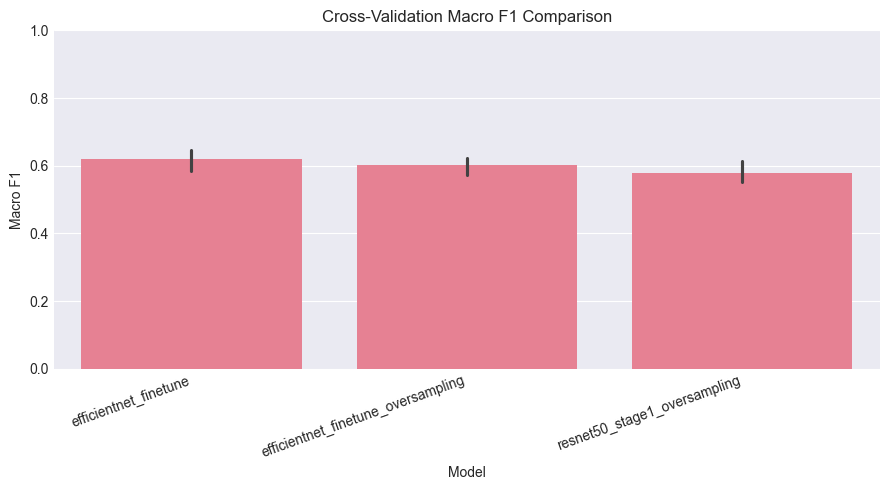

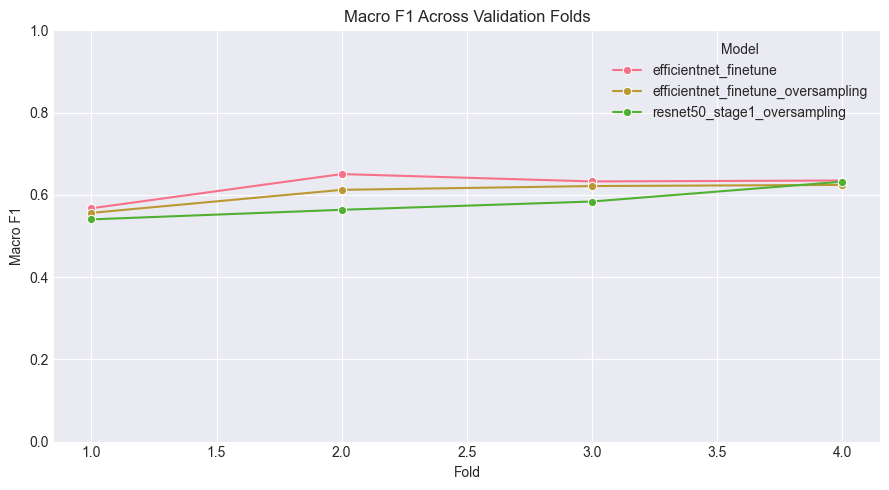

In [42]:
# ============================================================
# 7. MACRO F1 COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Macro F1"
)

plt.title("Cross-Validation Macro F1 Comparison")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

sns.lineplot(
    data=cv_results_df,
    x="Fold",
    y="Macro F1",
    hue="Model",
    marker="o"
)

plt.title("Macro F1 Across Validation Folds")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# 8. SELECT BEST MODEL
# ============================================================

SELECTED_MODEL = cv_summary.index[0]

FINAL_EPOCHS = int(
    cv_results_df.loc[
        cv_results_df["Model"] == SELECTED_MODEL,
        "Best Epoch"
    ].median()
)

print("Selected model:", SELECTED_MODEL)
print("Mean CV Macro F1:", round(cv_summary.loc[SELECTED_MODEL, "Macro F1_mean"], 4))
print("Final training epochs:", FINAL_EPOCHS)

Selected model: efficientnet_finetune
Mean CV Macro F1: 0.6213
Final training epochs: 15


## 11. Cross-Validation Results

EfficientNetB0 with partial fine-tuning and class weighting
achieved the highest mean Macro F1-score across the four folds.

| Model | Mean Macro F1 | Standard Deviation |
|---|---:|---:|
| EfficientNetB0 fine-tuning + class weights | 0.6213 | 0.0368 |
| EfficientNetB0 fine-tuning + oversampling | 0.6034 | 0.0319 |
| ResNet50 Stage 1 + oversampling | 0.5799 | 0.0390 |

EfficientNetB0 fine-tuning with class weighting is therefore
selected as the final image classification configuration.

The median best epoch across the four folds is 15.

In [50]:

# ============================================================
# 9. FINAL MODEL TRAINING
# ============================================================

# Ensure output directories exist
MODEL_DIR.mkdir(parents=True, exist_ok=True)
CV_RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Development data: folds 1, 2, 3, 4
final_train_idx = np.where(
    np.isin(df["fold"].to_numpy(), DEV_FOLDS)
)[0]

# Independent test data: fold 0
final_test_idx = np.where(
    df["fold"].to_numpy() == FINAL_TEST_FOLD
)[0]

# Basic checks
assert len(final_train_idx) > 0, "No final training samples found."
assert len(final_test_idx) > 0, "No final test samples found."

# Check patient-level separation
train_patients = set(df.iloc[final_train_idx]["patient_id"])
test_patients = set(df.iloc[final_test_idx]["patient_id"])

assert train_patients.isdisjoint(test_patients), \
    "Patient leakage detected between training and test data!"

print("Final training samples:", len(final_train_idx))
print("Final test samples:", len(final_test_idx))
print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))

# Select winning configuration
final_config = CV_MODELS[SELECTED_MODEL]



# Apply the same imbalance strategy used during CV
final_class_weight = None

if final_config["strategy"] == "oversampling":

    final_train_used = oversample_indices(
        final_train_idx, SEED
    )

else:

    final_train_used = final_train_idx

    # Recalculate class weights using ALL development folds
    final_class_weight = get_class_weights(
        final_train_idx
    )

print("\nSelected model:", SELECTED_MODEL)
print("Training strategy:", final_config["strategy"])
print("Final epochs:", FINAL_EPOCHS)
print("Class weights:", final_class_weight)

# Create final training dataset
final_train_ds = make_ds(
    final_train_used,
    training=True
)

# Clear previous models and set random seed
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

# Build a fresh model using the selected CV configuration
final_model, _ = build_cv_model(SELECTED_MODEL)

# Train on all four development folds
final_history = final_model.fit(
    final_train_ds,
    epochs=FINAL_EPOCHS,
    class_weight=final_class_weight,
    verbose=1
)

# Save final model weights
final_model.save_weights(
    MODEL_DIR / "final_selected_image_model_cv.weights.h5"
)

# Save final training history
pd.DataFrame(final_history.history).to_csv(
    CV_RESULT_DIR / "final_training_history.csv",
    index=False
)

print("\nFinal model training completed.")
print("Model weights and training history saved.")


Final training samples: 1803
Final test samples: 468
Training patients: 1096
Test patients: 275

Selected model: efficientnet_finetune
Training strategy: class_weights
Final epochs: 15
Class weights: {0: 0.5328014184397163, 1: 0.44584569732937684, 2: 6.988372093023256, 3: 1.5732984293193717, 4: 2.161870503597122, 5: 1.5651041666666667}
Trainable parameters: 3,459,362
Total parameters: 4,379,049.0
Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 23s 100ms/step - accuracy: 0.3849 - loss: 1.5653
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - accuracy: 0.5208 - loss: 1.1424
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.6023 - loss: 0.9347
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - accuracy: 0.6461 - loss: 0.8113
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.6705 - loss: 0.7131
Epoch 6/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - accuracy: 0.7249 - loss: 0.6172
Epoch 7/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 95ms/step - accuracy: 0.7377 - loss: 0.5973

## 12. Final Test Evaluation

The final model is evaluated once on the untouched test fold.

The evaluation includes:

- Accuracy and balanced accuracy.
- Macro and weighted F1-score.
- Macro precision and recall.
- Macro ROC-AUC.
- Matthews Correlation Coefficient.
- Per-class precision, recall, specificity and F1-score.
- Confusion matrix and ROC curves.

In [51]:

# ============================================================
# 10. FINAL TEST EVALUATION
# ============================================================

# Create test dataset (fold 0 only)
test_ds = make_ds(
    final_test_idx,
    training=False
)

y_test = y[final_test_idx]

# Predict test probabilities
test_probabilities = final_model.predict(
    test_ds,
    verbose=1
)

y_pred = np.argmax(
    test_probabilities,
    axis=1
)

# Check prediction dimensions
assert len(y_test) == len(y_pred)
assert test_probabilities.shape[1] == NUM_CLASSES

# Calculate evaluation metrics
test_metrics = evaluate_predictions(
    y_test,
    test_probabilities
)

print("\nFINAL TEST RESULTS")
print("=" * 45)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASSES,
    zero_division=0
))

# Save final test metrics
pd.DataFrame([test_metrics]).to_csv(
    CV_RESULT_DIR / "final_test_metrics.csv",
    index=False
)

print("\nTest metrics saved.")


15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 319ms/step

FINAL TEST RESULTS
Accuracy: 0.7179
Balanced Accuracy: 0.6593
Macro Precision: 0.6922
Macro Recall: 0.6593
Macro F1: 0.6732
Weighted F1: 0.7155
Macro ROC-AUC: 0.9110
MCC: 0.6157

Classification Report:

              precision    recall  f1-score   support

         ACK       0.79      0.81      0.80       159
         BCC       0.74      0.75      0.74       160
         MEL       0.86      0.67      0.75         9
         NEV       0.71      0.77      0.74        52
         SCC       0.41      0.37      0.39        46
         SEK       0.64      0.60      0.62        42

    accuracy                           0.72       468
   macro avg       0.69      0.66      0.67       468
weighted avg       0.71      0.72      0.72       468


Test metrics saved.


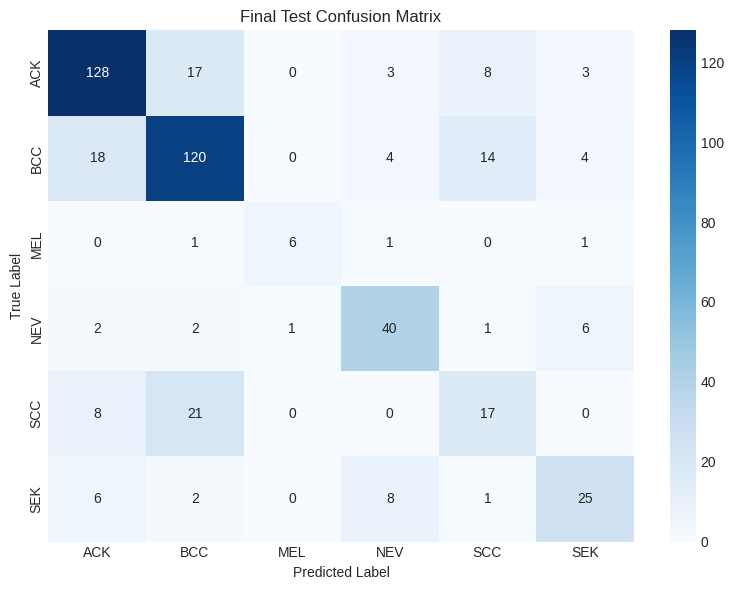

In [52]:

# ============================================================
# 11. FINAL TEST CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [55]:
# ============================================================
# 12. PER-CLASS EVALUATION
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    y_test, y_pred,
    labels=np.arange(NUM_CLASSES)
)

class_results = []

for i, cls in enumerate(CLASSES):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP

    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    class_results.append({
        "Class": cls,
        "Precision": report[cls]["precision"],
        "Recall": report[cls]["recall"],
        "Specificity": specificity,
        "F1-score": report[cls]["f1-score"],
        "Support": int(report[cls]["support"])
    })

class_results_df = pd.DataFrame(class_results)

display(class_results_df.round(4))

class_results_df.to_csv(
    CV_RESULT_DIR / "per_class_test_metrics.csv",
    index=False
)

,Class,Precision,Recall,Specificity,F1-score,Support
0,ACK,0.790100,0.805000,0.890000,0.797500,159
1,BCC,0.736200,0.750000,0.860400,0.743000,160
2,MEL,0.857100,0.666700,0.997800,0.750000,9
3,NEV,0.714300,0.769200,0.961500,0.740700,52
4,SCC,0.414600,0.369600,0.943100,0.390800,46
5,SEK,0.641000,0.595200,0.967100,0.617300,42


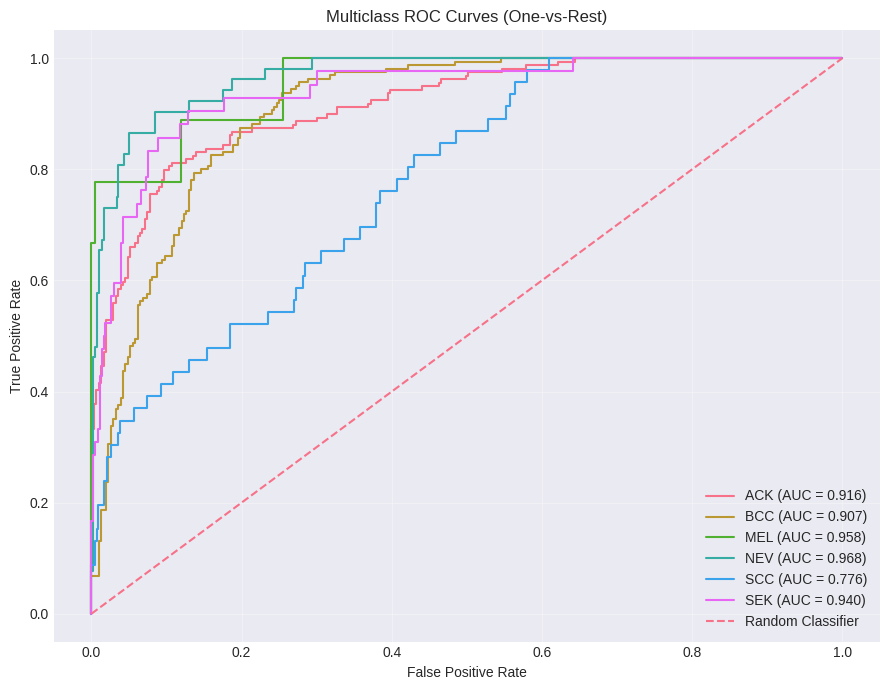

In [56]:
# ============================================================
# 13. MULTICLASS ROC-AUC CURVES
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(9, 7))

for i, cls in enumerate(CLASSES):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        test_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{cls} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    CV_RESULT_DIR / "final_test_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [58]:

# ============================================================
# 14. SAVE FINAL TEST PREDICTIONS
# ============================================================

test_predictions_df = pd.DataFrame({
    "Image": df.iloc[final_test_idx]["img_id"].values,
    "True Label": [CLASSES[i] for i in y_test],
    "Predicted Label": [CLASSES[i] for i in y_pred],
    "Correct": y_test == y_pred
})

# Save probability for each class
for i, cls in enumerate(CLASSES):
    test_predictions_df[f"Probability_{cls}"] = (
        test_probabilities[:, i]
    )

test_predictions_df.to_csv(
    CV_RESULT_DIR / "final_test_predictions.csv",
    index=False
)

pd.options.display.float_format = '{:.6f}'.format
display(test_predictions_df.head(10))

print("\nFinal test predictions saved.")


,Image,True Label,Predicted Label,Correct,Probability_ACK,Probability_BCC,Probability_MEL,Probability_NEV,Probability_SCC,Probability_SEK
0,PAT_684_1302_588.png,BCC,SCC,False,0.330915,0.231228,0.000076,0.002472,0.432517,0.002791
1,PAT_1995_4080_695.png,ACK,ACK,True,0.996854,0.002448,0.000012,0.000010,0.000085,0.000592
2,PAT_705_4015_413.png,ACK,ACK,True,0.999767,0.000106,0.000001,0.000000,0.000034,0.000093
3,PAT_2140_4726_141.png,ACK,ACK,True,0.984184,0.013713,0.000002,0.000033,0.002051,0.000017
4,PAT_1790_3425_942.png,SEK,SEK,True,0.000009,0.000000,0.000002,0.000426,0.000000,0.999563
5,PAT_435_854_68.png,BCC,BCC,True,0.022146,0.864727,0.000240,0.085695,0.026438,0.000754
6,PAT_134_201_587.png,BCC,BCC,True,0.014744,0.979261,0.000010,0.000072,0.005806,0.000108
7,PAT_724_1369_896.png,BCC,BCC,True,0.000333,0.996433,0.000016,0.001881,0.001305,0.000031
8,PAT_1842_3615_850.png,NEV,NEV,True,0.000003,0.000059,0.013133,0.986083,0.000005,0.000715
9,PAT_805_1517_154.png,SCC,ACK,False,0.984293,0.000779,0.000000,0.000000,0.014923,0.000004



Final test predictions saved.


## 13. Results, Limitations and Conclusion

The selected EfficientNetB0 model achieved a test Macro F1-score
of 0.6732 and a test accuracy of 0.7179.

Performance varies across diagnostic categories. In particular,
SCC remains a challenging class.

MEL has only nine images in the held-out test set, meaning that
its evaluation metrics have considerable uncertainty.

The results should therefore be interpreted in the context of
the dataset size, class imbalance and limited representation of
some diagnostic categories.

The final image model provides a baseline for comparison with
the metadata-only and multimodal classification approaches.